# Deep Learning Project 1: a residual CNN under 5M parameters

Team **jiaqi li nyu** (Jiaqi Li, NetID jl18215), NYU CS-GY 6953 / ECE-GY 7123 Deep Learning, Fall 2026.
Kaggle competition `cifar-10-res-net-architecture-challenge-dl`.

This notebook is the executed companion of the report (`report/main.tex`). It trains nothing. It

1. rebuilds the final network from `model.py` and prints its number of parameters and its architecture (Section 2.2);
2. loads the checkpoints of the two submitted models, recomputes their validation accuracy, regenerates both Kaggle
   submission files with `train.py predict` and compares the files' SHA-256 with the Kaggle receipts;
3. recomputes the validation results of Tables 3 to 5 from the published training logs and draws Figures 2 and 3;
4. recomputes every number of Section 3.5 (hidden test set) from the scores Kaggle returned;
5. recomputes the error analysis of Section 3.6 from the checkpoints and shows Figures 4 to 6;
6. ends with the final test accuracy and the number of parameters.

Two kinds of accuracy appear:

- **Validation accuracy** is measured on a fixed set of 5,000 official training images (500 per class) that no submitted
  model was trained on. It is computed here from the checkpoints and read from the training logs.
- **Test accuracy** is measured by Kaggle on the 2,000 hidden test images, whose labels we never see. The public half
  (1,000 images) was visible during the competition, and the private half (1,000 images) decides the final ranking. The
  final test accuracy of this project is the private score. These numbers are copied from Kaggle.

Wherever a number computed below is also quoted in the report, the report's value is compared with it, and the last
cell counts the comparisons.

In [1]:
import csv
import io
import json
import math
import os
import subprocess
import sys
import tempfile
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

from analysis import (CLASSES, confusion, load_checkpoint_model, load_submissions, validation_predictions,
                      validation_probabilities)
from model import ARCHITECTURES, CifarResNet, build_model, multiply_accumulates, parameter_count

ROOT = Path.cwd()
assert (ROOT / "train.py").exists() and (ROOT / "data/cache/audit.json").exists(), "run from the repository root with the prepared data"
FIGURES = ROOT / "report/figures"
DATA = FIGURES / "data"
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")

# Checkpoints are not in the repository. The checkpoint of a run is looked up as <dir>/<run>/last.pt in the colon-separated
# directories of PROJECT1_CHECKPOINTS. The default covers ./checkpoints (for the two released files) and the author's copies.
CHECKPOINT_DIRS = [Path(p) for p in os.environ.get(
    "PROJECT1_CHECKPOINTS", "checkpoints:../project1-hpc/artifacts/candidates:../project1-hpc/runs:runs").split(":")]
FINAL = {"KD2": dict(run="r2-kd2-ta1800-s2026", receipt=57959285, reported_validation=97.62,
                     method="knowledge distillation from two of our own networks (weight 0.9, temperature 4)"),
         "SAM": dict(run="sam-x4-1800-s2026", receipt=58002253, reported_validation=97.58,
                     method="sharpness-aware minimization (rho 0.05)")}
REPORT_NAME = {"resnet18-w32": "r18-w32", "resnet18-w42": "r18-w42", "resnet18-64-352": "r18-64-352", "resnet20-x4": "r20-x4",
               "resnet20-w68": "r20-w68", "resnet-highres": "highres", "preact-highres": "preact"}
CHECKS = []   # every comparison of a recomputed number with the value quoted in the report


def find_checkpoint(run):
    return next((d / run / "last.pt" for d in CHECKPOINT_DIRS if (d / run / "last.pt").exists()), None)


def check(what, computed, reported, digits=2, quiet=False):
    """Compare a recomputed number with the report's value; they agree when the report's value is its rounding."""
    agrees = abs(float(computed) - float(reported)) <= 0.5 * 10 ** -digits + 1e-9
    CHECKS.append((what, float(computed), float(reported), agrees))
    if not quiet:
        print(f"    {what}: {computed:,.{digits}f}   (report: {reported:,.{digits}f}){'' if agrees else '   <-- DIFFERS'}")
    return agrees


def summarize(start):
    """State how many of the comparisons made since position `start` agree with the report."""
    made = CHECKS[start:]
    differ = [(what, computed, reported) for what, computed, reported, agrees in made if not agrees]
    print(f"--> {len(made)} numbers compared with the report: " + ("all agree." if not differ else f"{len(differ)} differ: {differ}"))


def read_log(run):
    """Per-epoch records and resolved settings of a published run (cluster runs are in runs/hpc, laptop runs in runs)."""
    folder = next(p for p in (ROOT / "runs/hpc" / run, ROOT / "runs" / run) if (p / "metrics.jsonl").exists())
    metrics = [json.loads(line) for line in (folder / "metrics.jsonl").read_text().splitlines() if line.strip()]
    return metrics, json.loads((folder / "config.json").read_text())


def training_hours(run):
    return math.fsum(record["train_seconds"] for record in read_log(run)[0]) / 3600


def seconds_per_epoch(run):
    metrics = read_log(run)[0]
    return math.fsum(record["train_seconds"] for record in metrics) / len(metrics)


def show(path, width):
    display(Image(filename=str(path), width=width))


print("torch", torch.__version__, "| device", device)
for key, item in FINAL.items():
    item["checkpoint"] = find_checkpoint(item["run"])
    print(f"{key}: checkpoint {item['checkpoint'] if item['checkpoint'] else 'NOT FOUND (the cells that need it are skipped)'}")

torch 2.15.0 | device mps
KD2: checkpoint ../project1-hpc/artifacts/candidates/r2-kd2-ta1800-s2026/last.pt
SAM: checkpoint ../project1-hpc/artifacts/candidates/sam-x4-1800-s2026/last.pt


## Data and the validation set (Section 2.1)

The 50,000 official training images (5,000 per class) were split once, stratified by class with random seed 2026, into
45,000 training images and 5,000 validation images. The normalization statistics use the 45,000 training images only, and
no pixel-identical image appears on both sides of the split. Every checkpoint stores this record, and `train.py` refuses
data whose record differs. Training and validation never use the hidden test images, and the final pipeline reads them
only through `train.py predict`, which writes the submission files. The README (Rules and scope) lists every other use of
the test images during the project.

In [2]:
audit = json.loads((ROOT / "data/cache/audit.json").read_text())
print("training images:", audit["training_split"], "| validation images:", audit["validation_split"], "| split seed:", audit["split_seed"])
print("validation images per class:", audit["validation_class_counts"])
print("hidden test images:", audit["test_images"], "| test labels accessed:", audit["test_labels_accessed"])
print("normalization mean:", np.round(audit["normalization_training_only_mean"], 4), "std:", np.round(audit["normalization_training_only_std"], 4))
print("pixel-identical training images that had to be kept out of the validation set:", len(audit["train_duplicates_excluded_to_avoid_validation_leakage"]))
print(f"one standard error of an accuracy of 97.6% on 5,000 images: {100 * math.sqrt(0.976 * 0.024 / 5000):.2f} points; "
      f"of 89% on 1,000 images: {100 * math.sqrt(0.89 * 0.11 / 1000):.2f} points")

training images: 45000 | validation images: 5000 | split seed: 2026
validation images per class: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
hidden test images: 2000 | test labels accessed: False
normalization mean: [0.4915 0.4823 0.4468] std: [0.2471 0.2435 0.2615]
pixel-identical training images that had to be kept out of the validation set: 0
one standard error of an accuracy of 97.6% on 5,000 images: 0.22 points; of 89% on 1,000 images: 0.99 points


## Network architecture (Section 2.2, Table 1, Figure 1)

Every network is built from the residual block of the assignment, `ReLU(S(x) + F(x))` with `F = conv-BN-ReLU-conv-BN`.
`S` is the identity, or a 1x1 convolution with batch normalization in the first block of a stage that halves the
resolution (`preact` uses full pre-activation blocks). A 3x3 convolution starts the network, and global average pooling
and one linear layer end it. The final architecture, `resnet20-x4` (`r20-x4` in the report), is the three-stage CIFAR
ResNet-20 of He et al. with three blocks per stage and four times the original number of channels.

The cell below rebuilds Table 1. All trainable parameters are counted, including batch normalization and the classifier.
The time per epoch is the logged training time per epoch on an A100 with 45,000 images, one value per run (for `r20-w68`
it is scaled from its run on 50,000 images); Table 1 quotes these times rounded to 0.1 s.

In [3]:
TABLE1 = {  # architecture: parameters (millions) and multiply-accumulate operations (millions) in Table 1, runs that time it
    "resnet18-w32": (2.80, 139, []), "resnet18-64-352": (4.80, 453, ["cloud-r18-800-s2026"]),
    "resnet20-x4": (4.33, 648, ["r2-ta1800-s2026", "r2-ta1800-s2027"]), "resnet20-w68": (4.88, 731, ["w68-full-s2026"]),
    "resnet-highres": (3.53, 956, ["r2-highres400-s2026", "r2-highres400-s2027"]),
    "preact-highres": (3.53, 956, ["r2-preact400-s2026", "r2-preact400-s2027"])}
start = len(CHECKS)
print(f"{'report name':12s} {'name in model.py':16s} {'channels per stage':20s} {'blocks':13s} {'parameters':>10s} {'MACs':>8s}  s/epoch on an A100")
reference = CifarResNet(64)  # ResNet-18 with a 3x3 first convolution: shown in Table 1 for reference, not trained
print(f"{'ResNet-18':12s} {'(reference)':16s} {'(64, 128, 256, 512)':20s} {'(2, 2, 2, 2)':13s} {parameter_count(reference):>10,} {multiply_accumulates(reference) / 1e6:>7.0f}M  -")
check("ResNet-18 parameters (millions)", parameter_count(reference) / 1e6, 11.17, quiet=True)
check("ResNet-18 multiply-accumulate operations (millions)", multiply_accumulates(reference) / 1e6, 555, 0, quiet=True)
for name, spec in ARCHITECTURES.items():
    network = build_model(name)
    count, operations = parameter_count(network), multiply_accumulates(network)
    assert count <= 5_000_000
    times = [seconds_per_epoch(run) * 45000 / read_log(run)[1]["train_images"] for run in TABLE1.get(name, (0, 0, []))[2]]
    print(f"{REPORT_NAME[name]:12s} {name:16s} {str(spec['widths']):20s} {str(spec['depths']):13s} {count:>10,} {operations / 1e6:>7.0f}M  "
          f"{' / '.join(f'{t:.2f}' for t in times) or '-'}")
    if name in TABLE1:
        check(f"{name} parameters (millions)", count / 1e6, TABLE1[name][0], quiet=True)
        check(f"{name} multiply-accumulate operations (millions)", operations / 1e6, TABLE1[name][1], 0, quiet=True)
summarize(start)

report name  name in model.py channels per stage   blocks        parameters     MACs  s/epoch on an A100
ResNet-18    (reference)      (64, 128, 256, 512)  (2, 2, 2, 2)  11,173,962     555M  -
r18-w32      resnet18-w32     (32, 64, 128, 256)   (2, 2, 2, 2)   2,797,610     139M  -
r18-w42      resnet18-w42     (42, 84, 168, 336)   (2, 2, 2, 2)   4,815,940     240M  -


r18-64-352   resnet18-64-352  (64, 128, 256, 352)  (2, 2, 2, 1)   4,797,002     453M  3.53
r20-x4       resnet20-x4      (64, 128, 256)       (3, 3, 3)      4,327,754     648M  3.93 / 3.98
r20-w68      resnet20-w68     (68, 136, 272)       (3, 3, 3)      4,884,926     731M  5.14
highres      resnet-highres   (96, 160, 224)       (3, 3, 2)      3,527,082     956M  5.24 / 5.23
preact       preact-highres   (96, 160, 224)       (3, 3, 2)      3,526,314     956M  5.14 / 5.17
--> 14 numbers compared with the report: all agree.


The final network and the statements of Section 2.2 about how the parameters are distributed. One residual block of each
kind is printed: the first block of stage 1 keeps the resolution and uses the identity as `S`, and the first block of
stage 2 halves the resolution with a stride-2 convolution and uses a 1x1 convolution with batch normalization as `S`.

In [4]:
def parameters_of(modules):
    return sum(p.numel() for module in modules for p in module.parameters() if p.requires_grad)


final_model = build_model("resnet20-x4")
final_parameters = parameter_count(final_model)
start = len(CHECKS)
print(f"Final network resnet20-x4: {final_parameters:,} trainable parameters (limit 5,000,000), "
      f"{multiply_accumulates(final_model) / 1e6:.0f}M multiply-accumulate operations per 32x32 image\n")
parts = [("first 3x3 convolution with batch normalization", [final_model.stem], 1856),
         ("stage 1: 3 blocks, 64 channels, 32x32", final_model.blocks[0:3], 221952),
         ("stage 2: 3 blocks, 128 channels, 16x16", final_model.blocks[3:6], 820992),
         ("stage 3: 3 blocks, 256 channels, 8x8", final_model.blocks[6:9], 3280384),
         ("classifier (global average pooling, linear layer)", [final_model.head], 2570)]
for name, modules, reported in parts:
    print(f"{name:52s} {parameters_of(modules):>10,}")
    check(name, parameters_of(modules), reported, 0, quiet=True)
print(f"{'total':52s} {final_parameters:>10,}\n")
check("parameters of the final network", final_parameters, 4327754, 0)
trimmed = build_model("resnet18-64-352")
check("parameters in the fourth stage of ResNet-18 (millions)", parameters_of(reference.blocks[6:8]) / 1e6, 8.4, 1)
check("parameters of r18-64-352", parameter_count(trimmed), 4797002, 0)
check("r18-64-352, share of the multiply-accumulate operations of ResNet-18 (%)", 100 * multiply_accumulates(trimmed) / multiply_accumulates(reference), 82, 0)
check("r20-x4 against r18-64-352: fewer parameters (%)", 100 * (1 - final_parameters / parameter_count(trimmed)), 10, 0)
check("r20-x4 against r18-64-352: more multiply-accumulate operations (%)", 100 * (multiply_accumulates(final_model) / multiply_accumulates(trimmed) - 1), 43, 0)
check("r20-w68, share of the parameter limit (%)", 100 * parameter_count(build_model("resnet20-w68")) / 5e6, 98, 0)
summarize(start)
print("\nfirst block of stage 1:\n", final_model.blocks[0])
print("\nfirst block of stage 2:\n", final_model.blocks[3])

Final network resnet20-x4: 4,327,754 trainable parameters (limit 5,000,000), 648M multiply-accumulate operations per 32x32 image

first 3x3 convolution with batch normalization            1,856
stage 1: 3 blocks, 64 channels, 32x32                   221,952
stage 2: 3 blocks, 128 channels, 16x16                  820,992
stage 3: 3 blocks, 256 channels, 8x8                  3,280,384
classifier (global average pooling, linear layer)         2,570
total                                                 4,327,754

    parameters of the final network: 4,327,754   (report: 4,327,754)
    parameters in the fourth stage of ResNet-18 (millions): 8.4   (report: 8.4)
    parameters of r18-64-352: 4,797,002   (report: 4,797,002)
    r18-64-352, share of the multiply-accumulate operations of ResNet-18 (%): 82   (report: 82)
    r20-x4 against r18-64-352: fewer parameters (%): 10   (report: 10)
    r20-x4 against r18-64-352: more multiply-accumulate operations (%): 43   (report: 43)
    r20-w68, shar

**Figure 1 of the report: the final pipeline.** (a) Data and the augmentation applied at each training step. (b) The
`r20-x4` network. (c) The training objective: cross-entropy with label smoothing, optionally combined with the
distillation loss or the two-pass sharpness-aware update. (d) Inference with the averaged weights and the mean of the
logits of each image and its mirror image. The figure is drawn by `report/figures/make_pipeline.py` from `model.py`,
the configurations and one training image; the committed file is shown.

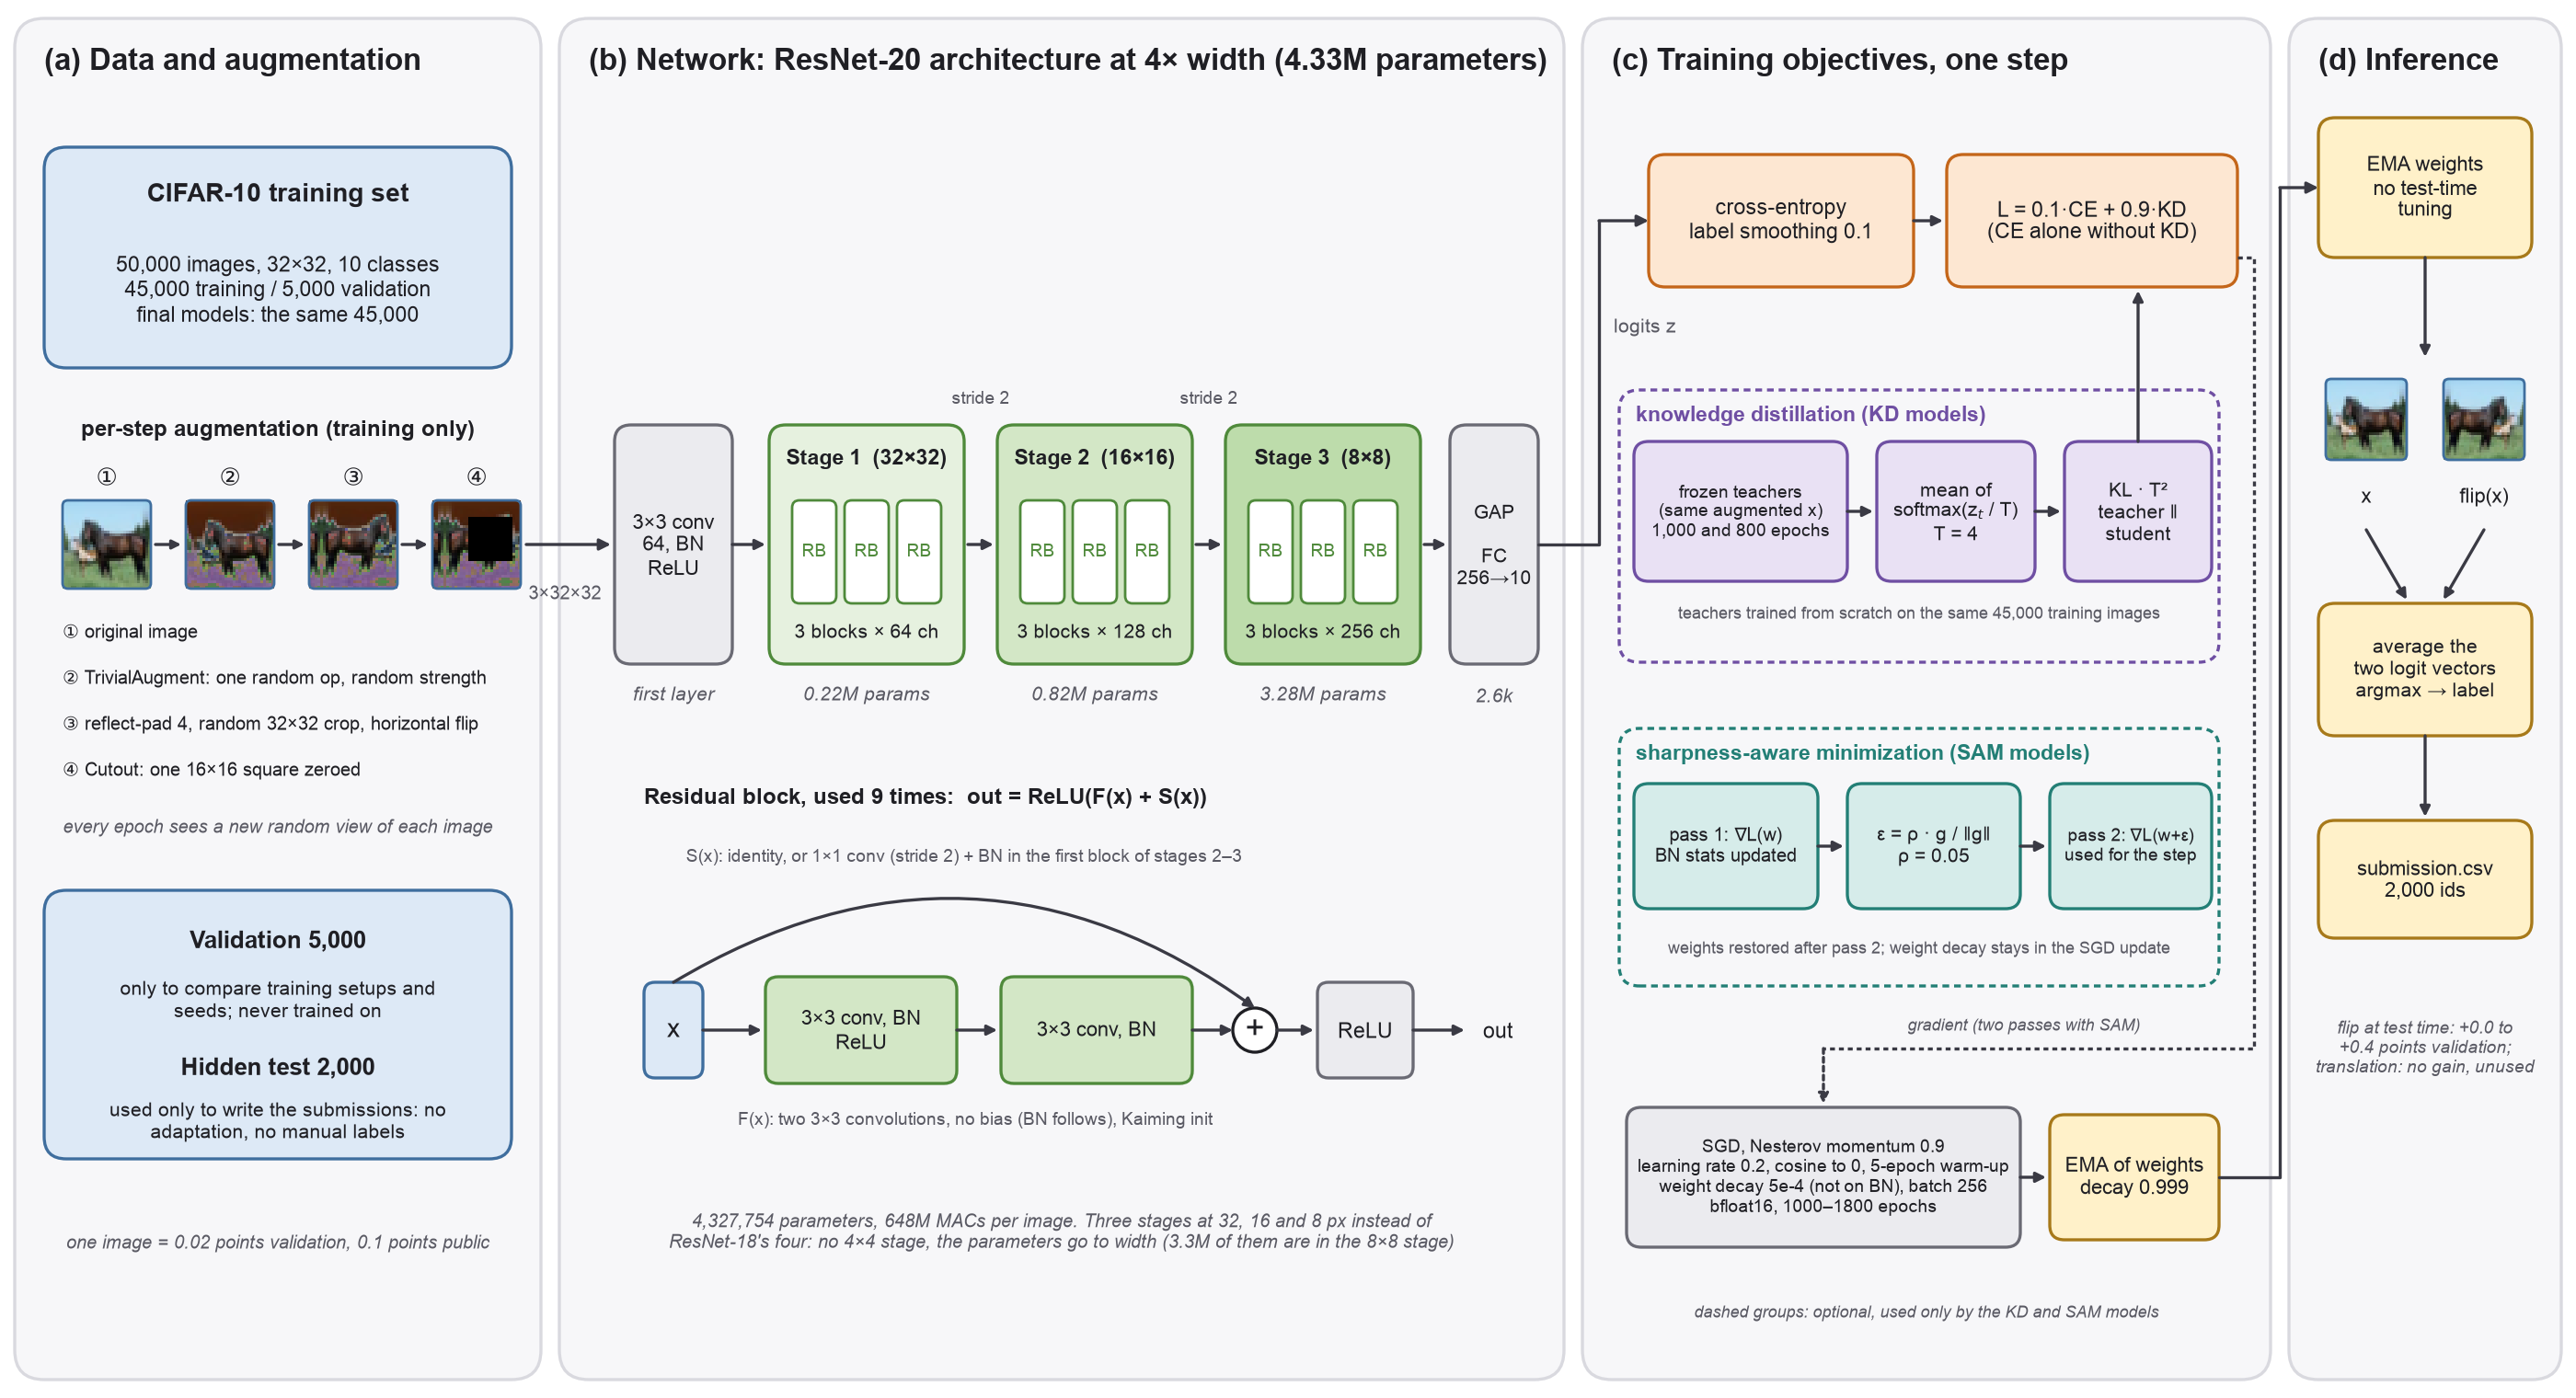

In [5]:
show(FIGURES / "pipeline.png", 1000)

## Training procedure (Section 2.3, Table 2)

Both submitted models use `configs/final-1800.json`: SGD with Nesterov momentum 0.9, batch size 256, a peak learning rate of
0.2 after a five-epoch linear warm-up, one cosine decay to zero over 1,800 epochs updated at every step, weight decay 5e-4
on the weights of convolutional and linear layers only, TrivialAugmentWide, a random crop after reflection padding, a
random horizontal flip, a 16x16 Cutout square, label smoothing 0.1, an exponential moving average (EMA) of the weights
with decay 0.999 per step, which is used for evaluation and prediction, and mixed precision with bfloat16. The report
calls this procedure without distillation or SAM *standard training*. The baseline of the course is listed beside it.

In [6]:
baseline, final_procedure = (json.loads((ROOT / "configs" / name).read_text()) for name in ("baseline.json", "final-1800.json"))
print(f"{'setting':20s} {'baseline':18s} {'final':18s}")
for key in sorted(set(baseline) | set(final_procedure)):
    print(f"{key:20s} {str(baseline.get(key, '-')):18s} {str(final_procedure.get(key, '-')):18s}")
print("\nCommands that trained the two submitted models and the two teachers (one A100 each; README, Reproducing the final models):")
print("  teachers: train.py train --config configs/improved.json --arch resnet20-x4 --epochs 1000 --seed 2026 --channels-last --eval-every 10 --no-eval-raw --run runs/cloud-x4-1000-s2026 --device cuda")
print("            train.py train --config configs/improved.json --arch resnet20-x4 --epochs 800 --seed 2027 --channels-last --eval-every 10 --no-eval-raw --run runs/cloud-x4-800-s2027 --device cuda")
print("  KD2:      train.py train --config configs/final-1800.json --seed 2026 --teachers runs/cloud-x4-1000-s2026/last.pt runs/cloud-x4-800-s2027/last.pt --kd-alpha 0.9 --kd-temperature 4 --run runs/r2-kd2-ta1800-s2026 --device cuda")
print("  SAM:      train.py train --config configs/final-1800.json --seed 2026 --sam-rho 0.05 --run runs/sam-x4-1800-s2026 --device cuda")

setting              baseline           final             
amp                  none               bf16              
arch                 resnet18-w32       resnet20-x4       
batch_size           128                256               
bn_weight_decay      True               False             
channels_last        -                  True              
cutout               0                  16                
ema_decay            0.0                0.999             
epoch_seeded_policy  -                  True              
epochs               100                1800              
eval_every           -                  10                
eval_raw             -                  False             
label_smoothing      0.0                0.1               
lr                   0.1                0.2               
lr_per_step          False              True              
padding_mode         constant           reflect           
pipeline             batched            trivialaugment  

## Distillation teachers, training time and computing resources (Sections 2.4 to 2.6)

The KD2 models learn from two of our own networks, `r20-x4` with standard training for 1,000 epochs (seed 2026) and for
800 epochs (seed 2027); the KD5 models add three more teachers. The cell recomputes the accuracy of the averaged
predictions of the teachers from their checkpoints when these are available (they are not part of the release), the extra
time that distillation and SAM add to a training step, and the total training time of the runs.

In [7]:
start = len(CHECKS)
TEACHERS = ["cloud-x4-1000-s2026", "cloud-x4-800-s2027", "cloud-x4-1600-s2026", "x4-400ep-45k", "cloud-r18-800-s2026"]  # KD2 uses the first two
for run, reported in zip(TEACHERS[:2], (97.54, 97.50)):
    check(f"teacher {run}, validation accuracy (%)", 100 * read_log(run)[0][-1]["tta_valid_accuracy"], reported)
check("parameters of the two KD2 teachers together (millions)", 2 * final_parameters / 1e6, 8.66)
teacher_probabilities = {}
for run in TEACHERS:
    if find_checkpoint(run) is not None:
        teacher, _ = load_checkpoint_model(str(find_checkpoint(run)), device)
        teacher_probabilities[run], validation_labels = validation_probabilities(teacher, device)
for members, reported in ((TEACHERS[:2], 97.84), (TEACHERS, 97.96)):
    if all(run in teacher_probabilities for run in members):
        average = np.mean([teacher_probabilities[run] for run in members], axis=0)
        check(f"average prediction of the {len(members)} teachers, validation accuracy (%)", 100 * (average.argmax(1) == validation_labels).mean(), reported)
    else:
        print(f"    average prediction of the {len(members)} teachers: their checkpoints are not available, skipped (report: {reported})")

standard_epoch = np.mean([seconds_per_epoch(run) for run in ("r2-ta1800-s2026", "r2-ta1800-s2027")])
check("KD2 training step, slower than standard training (%)", 100 * (seconds_per_epoch("r2-kd2-ta1800-s2026") / standard_epoch - 1), 28, 0)
check("KD5 training step, slower than standard training (%)", 100 * (seconds_per_epoch("r2-kd5-ta1800-s2026") / standard_epoch - 1), 73, 0)
check("SAM epoch on the A100 (seconds)", seconds_per_epoch("sam-x4-1800-s2026"), 6.4, 1)
check("standard epoch on the A100 (seconds)", standard_epoch, 4.0, 1)
check("SAM epoch / standard epoch", seconds_per_epoch("sam-x4-1800-s2026") / standard_epoch, 1.6, 1)

cluster_runs = sorted(p.name for p in (ROOT / "runs/hpc").iterdir() if (p / "metrics.jsonl").exists())
laptop_runs = sorted(p.name for p in (ROOT / "runs").iterdir() if p.name != "hpc" and (p / "metrics.jsonl").exists())
check("runs on the cluster", len(cluster_runs), 36, 0)
check("A100 hours of training steps in these runs", sum(training_hours(run) for run in cluster_runs), 56, 0)
laptop_validated = [run for run in laptop_runs if read_log(run)[1].get("validation_held_out", True)]
print(f"    laptop: {sum(training_hours(run) for run in laptop_runs):.1f} hours of training steps in {len(laptop_runs)} runs, "
      f"{sum(training_hours(run) for run in laptop_validated):.1f} hours without the run on all 50,000 images   (report: about 17)")
summarize(start)

    teacher cloud-x4-1000-s2026, validation accuracy (%): 97.54   (report: 97.54)
    teacher cloud-x4-800-s2027, validation accuracy (%): 97.50   (report: 97.50)
    parameters of the two KD2 teachers together (millions): 8.66   (report: 8.66)


    average prediction of the 2 teachers, validation accuracy (%): 97.84   (report: 97.84)
    average prediction of the 5 teachers, validation accuracy (%): 97.96   (report: 97.96)
    KD2 training step, slower than standard training (%): 28   (report: 28)
    KD5 training step, slower than standard training (%): 73   (report: 73)
    SAM epoch on the A100 (seconds): 6.4   (report: 6.4)
    standard epoch on the A100 (seconds): 4.0   (report: 4.0)
    SAM epoch / standard epoch: 1.6   (report: 1.6)
    runs on the cluster: 36   (report: 36)
    A100 hours of training steps in these runs: 56   (report: 56)


    laptop: 22.0 hours of training steps in 14 runs, 16.9 hours without the run on all 50,000 images   (report: about 17)
--> 12 numbers compared with the report: all agree.


## The two submitted models: validation accuracy recomputed from the checkpoints

Each checkpoint holds the model, the EMA of its weights, the optimizer and random-number-generator states, the data
record and the resolved settings. The network is rebuilt from the architecture name stored in the checkpoint, the EMA
weights are loaded, and the accuracy on the 5,000 validation images is recomputed with and without flip test-time
augmentation, the mean of the logits of each image and its horizontal mirror image. The report quotes the values with it.

In [8]:
start = len(CHECKS)
for key, item in FINAL.items():
    if item["checkpoint"] is None:
        print(f"{key}: checkpoint not available, skipped")
        continue
    model, checkpoint = load_checkpoint_model(str(item["checkpoint"]), device)  # EMA weights by default
    config = checkpoint["config"]
    assert config["validation_held_out"] and config["train_images"] == 45000 and checkpoint["epoch"] == config["epochs"]
    without_flip, labels = validation_predictions(model, device, "none")
    with_flip, _ = validation_predictions(model, device, "flip")
    print(f"{key} ({item['run']}): {config['arch']}, {parameter_count(model):,} parameters, epoch {checkpoint['epoch']} of {config['epochs']}, "
          f"trained on {config['train_images']:,} images and never on the validation images")
    print(f"    training method: {item['method']}")
    print(f"    EMA weights without flip test-time augmentation: {100 * (without_flip == labels).mean():.2f}%; "
          f"with it: {(with_flip == labels).sum():,} of {len(labels):,} validation images correct")
    check(f"{key} validation accuracy with flip test-time augmentation (%)", 100 * (with_flip == labels).mean(), item["reported_validation"])
    print(f"    revision of the code that trained it: train.py {config['code_sha256']['train.py'][:12]}, model.py {config['code_sha256']['model.py'][:12]}")
summarize(start)

KD2 (r2-kd2-ta1800-s2026): resnet20-x4, 4,327,754 parameters, epoch 1800 of 1800, trained on 45,000 images and never on the validation images
    training method: knowledge distillation from two of our own networks (weight 0.9, temperature 4)
    EMA weights without flip test-time augmentation: 97.46%; with it: 4,881 of 5,000 validation images correct
    KD2 validation accuracy with flip test-time augmentation (%): 97.62   (report: 97.62)
    revision of the code that trained it: train.py bf50b73740c9, model.py b7c1165e846b


SAM (sam-x4-1800-s2026): resnet20-x4, 4,327,754 parameters, epoch 1800 of 1800, trained on 45,000 images and never on the validation images
    training method: sharpness-aware minimization (rho 0.05)
    EMA weights without flip test-time augmentation: 97.56%; with it: 4,879 of 5,000 validation images correct
    SAM validation accuracy with flip test-time augmentation (%): 97.58   (report: 97.58)
    revision of the code that trained it: train.py a05918027451, model.py b7c1165e846b
--> 2 numbers compared with the report: all agree.


## The two submission files, regenerated and matched to the Kaggle receipts

`train.py predict` is the code that reads the hidden test images in the final pipeline. It is run here exactly as it was
run for the uploads (EMA weights, flip test-time augmentation, batch size 256) and writes each CSV into a temporary folder.
The SHA-256 of the regenerated file is compared with the hash recorded in the Kaggle receipt of the upload, and
`check_submission.py` reads the file again independently (header, 2,000 rows in the order of `sample_submission.csv`,
labels 0 to 9, parameter limit) and lists the receipts that match it.

In [9]:
receipts = {r["submission_ref"]: r for r in load_submissions()}
for key, item in FINAL.items():
    if item["checkpoint"] is None:
        print(f"{key}: checkpoint not available, skipped")
        continue
    receipt = receipts[item["receipt"]]
    with tempfile.TemporaryDirectory() as folder:
        output = Path(folder) / item["run"] / "submission.csv"
        command = [sys.executable, "train.py", "predict", "--checkpoint", str(item["checkpoint"]), "--output", str(output),
                   "--weights", "ema", "--tta", "flip", "--device", device.type, "--batch-size", "256"]
        print(f"{key}: $ python train.py predict --checkpoint {item['checkpoint']} --output <tmp>/submission.csv --weights ema --tta flip --device {device.type} --batch-size 256")
        prediction = json.loads(subprocess.run(command, check=True, capture_output=True, text=True).stdout)
        independent = json.loads(subprocess.run([sys.executable, "check_submission.py", str(output)], check=True, capture_output=True, text=True).stdout)
    identical = prediction["sha256"] == receipt["csv_sha256"]
    print(f"    regenerated: {prediction['rows']} rows, validation accuracy of these weights {100 * prediction['valid_accuracy_of_these_weights']:.2f}%, "
          f"predicted class counts {prediction['predicted_class_counts']}")
    print(f"    SHA-256 regenerated   {prediction['sha256']}")
    print(f"    SHA-256 Kaggle upload {receipt['csv_sha256']} (submission {receipt['submission_ref']}, uploaded {receipt['submitted_utc'][:10]})")
    print(f"    -> {'IDENTICAL to the uploaded file' if identical else 'DIFFERENT from the uploaded file'}; independent check: "
          f"ids match {independent['ids_match_sample_submission']}, labels valid {independent['labels_valid']}, "
          f"receipts for this file {[r['submission_ref'] for r in independent['kaggle_receipts_for_this_file']]}")
    assert identical

KD2: $ python train.py predict --checkpoint ../project1-hpc/artifacts/candidates/r2-kd2-ta1800-s2026/last.pt --output <tmp>/submission.csv --weights ema --tta flip --device mps --batch-size 256


    regenerated: 2000 rows, validation accuracy of these weights 97.62%, predicted class counts [171, 217, 210, 211, 198, 212, 178, 202, 201, 200]
    SHA-256 regenerated   e50ca98dd471606492eafec432da509c5d5967105c880a0ce98eb162fc7b39a1
    SHA-256 Kaggle upload e50ca98dd471606492eafec432da509c5d5967105c880a0ce98eb162fc7b39a1 (submission 57959285, uploaded 2026-11-03)
    -> IDENTICAL to the uploaded file; independent check: ids match True, labels valid True, receipts for this file [57959285]
SAM: $ python train.py predict --checkpoint ../project1-hpc/artifacts/candidates/sam-x4-1800-s2026/last.pt --output <tmp>/submission.csv --weights ema --tta flip --device mps --batch-size 256


    regenerated: 2000 rows, validation accuracy of these weights 97.58%, predicted class counts [171, 220, 214, 210, 198, 205, 178, 202, 201, 201]
    SHA-256 regenerated   7aec582b09645ecdd1c983491c350bb87e08fc6be5408f7ecca8ea6cbf62f2ee
    SHA-256 Kaggle upload 7aec582b09645ecdd1c983491c350bb87e08fc6be5408f7ecca8ea6cbf62f2ee (submission 58002253, uploaded 2026-11-05)
    -> IDENTICAL to the uploaded file; independent check: ids match True, labels valid True, receipts for this file [58002253]


## Validation results (Sections 3.1 to 3.4)

### The data file of the report against the published training logs

`report/figures/data/experiments.csv` holds the validation accuracy and the training time on the A100 of every completed
run, and its `source` column names the run behind each number. Those runs are published with their per-epoch
`metrics.jsonl` as `runs/hpc/<name>/` (cluster) and `runs/<name>/` (laptop). Each row is recomputed here from the log:
the accuracy of the EMA weights with flip test-time augmentation at the last epoch, and the sum of the logged training-step
times. Tables 3 to 5 and Figure 2 are built from this file.

In [10]:
experiments = list(csv.DictReader((DATA / "experiments.csv").open()))
SCREENING = {("TA 400", "2026"): "r2-ta400-s2026", ("TA 400", "2027"): "r2-ta400-s2027", ("AA 400", "2026"): "r2-aa400-s2026",
             ("AA 400", "2027"): "r2-aa400-s2027", ("RA 400", "2026"): "r2-ra400-s2026", ("RA 400", "2027"): "r2-ra400-s2027",
             ("HighRes 400", "2026"): "r2-highres400-s2026", ("HighRes 400", "2027"): "r2-highres400-s2027",
             ("PreAct 400", "2026"): "r2-preact400-s2026", ("PreAct 400", "2027"): "r2-preact400-s2027",
             ("CE 1800", "2027"): "r2-ta1800-s2027", ("AA 1800", "2026"): "r2-aa1800-s2026"}


def run_of(row):
    """Name of the published run behind a row of experiments.csv (the `source` column names its original folder)."""
    if "cloud-evidence" in row["source"] or "screening" in row["source"]:
        return SCREENING[(row["label"], row["seed"])]
    return row["source"].split(" ")[0].rstrip("/").split("/")[-1]


def method_of(label):
    """The training method of a row in the report's terms (the labels in the data files are older abbreviations)."""
    first = label.split()[0]
    if first in ("KD", "KD2", "KD5", "SAM"):
        return first
    return {"AA": "AutoAugment", "RA": "RandAugment"}.get(first, "baseline training" if "baseline" in label else "standard training")


print(f"{'published run':30s} {'architecture':11s} {'method':18s} {'epochs':>6s} {'seed':>5s} {'validation %':>13s} {'from the log':>13s} {'A100 hours':>11s} {'from the log':>13s}")
differences = []
for row in experiments:
    run = run_of(row)
    metrics = read_log(run)[0]
    accuracy, hours = 100 * metrics[-1]["tta_valid_accuracy"], math.fsum(r["train_seconds"] for r in metrics) / 3600
    print(f"{run:30s} {REPORT_NAME[row['arch']]:11s} {method_of(row['label']):18s} {int(row['epochs']):>6,} {row['seed']:>5s} {float(row['heldout']):>13.2f} "
          f"{accuracy:>13.2f} {row['a100_hours'] or ('laptop' if row['device'] == 'mps' else ''):>11s} {f'{hours:.3f}' if row['device'] == 'a100' else '':>13s}")
    if abs(accuracy - float(row["heldout"])) > 1e-9:
        differences.append((run, "validation", row["heldout"], round(accuracy, 2)))
    if row["a100_hours"]:
        decimals = len(row["a100_hours"].split(".")[1]) if "." in row["a100_hours"] else 0
        if abs(hours - float(row["a100_hours"])) > 0.5 * 10 ** -decimals + 1e-9:
            differences.append((run, "hours", row["a100_hours"], round(hours, 3)))
print(f"\n{len(experiments)} rows of experiments.csv compared with the logs. Values that differ from the log: {differences or 'none'}.")

published run                  architecture method             epochs  seed  validation %  from the log  A100 hours  from the log
improved100-resnet20-x4        r20-x4      standard training     100  2026         96.72         96.72      laptop              
x4-400ep-45k                   r20-x4      standard training     400  2026         97.28         97.28      laptop              
cloud-x4-400-s2026             r20-x4      standard training     400  2026         97.24         97.24       0.404         0.404
r2-ta400-s2026                 r20-x4      standard training     400  2026         97.36         97.36       0.430         0.430
r2-ta400-s2027                 r20-x4      standard training     400  2027         97.32         97.32       0.451         0.451
cloud-x4-800-s2026             r20-x4      standard training     800  2026         97.30         97.30       0.822         0.822
cloud-x4-800-s2027             r20-x4      standard training     800  2027         97.50        

### Table 3: from the baseline to the final procedure

The changes in the order in which they were made, with random seed 2026 throughout. Validation accuracy comes from
`experiments.csv` and, for the two half-width networks, from the evaluation written at prediction time; public accuracy is
Kaggle's score on the public half of the test set.

In [11]:
submissions = list(csv.DictReader((DATA / "submissions.csv").open()))
by_ref = {int(row["kaggle_ref"]): row for row in submissions}
TABLE3 = [  # model, change, Kaggle reference (None: not uploaded), validation and public accuracy in Table 3
    ("resnet18-w32", "baseline training", 100, 57795621, 94.84, 83.8), ("resnet18-w32", "+ final procedure", 100, 57799551, 94.72, 85.0),
    ("resnet18-64-352", "+ full-width stages 1-3", 100, 57784806, 96.42, 86.3), ("resnet20-x4", "+ three stages", 100, 57799552, 96.72, 86.6),
    ("resnet20-x4", "+ 400 epochs", 400, None, 97.28, None), ("resnet20-x4", "+ 1,000 epochs (A100)", 1000, 57858708, 97.54, 89.5),
    ("resnet20-x4", "+ 1,800 epochs", 1800, 57958368, 97.66, 88.6), ("resnet20-x4", "+ distillation, two teachers", 1800, 57959285, 97.62, 90.1),
    ("resnet20-x4", "SAM instead of distillation", 1800, 58002253, 97.58, 90.0)]
start = len(CHECKS)
print(f"{'model':11s} {'change':30s} {'parameters':>10s} {'epochs':>6s} {'validation':>10s} {'public':>7s}")
for arch, change, epochs, ref, validation, public in TABLE3:
    row = by_ref.get(ref)
    measured = float(row["heldout"]) if row else 100 * read_log("x4-400ep-45k")[0][-1]["tta_valid_accuracy"]
    assert row is None or (row["arch"], int(row["epochs"])) == (arch, epochs)
    print(f"{REPORT_NAME[arch]:11s} {change:30s} {parameter_count(build_model(arch)) / 1e6:>9.2f}M {epochs:>6,} {measured:>10.2f} {row['public'] if row else '-':>7s}")
    check(f"Table 3, {change}: validation", measured, validation, quiet=True)
    if row:
        check(f"Table 3, {change}: public", float(row["public"]), public, 1, quiet=True)
for run, reported in (("baseline-100ep", 99.9), ("improved100-resnet18-w32", 84.8)):
    check(f"accuracy on the training batches at the end of {run} (%)", 100 * read_log(run)[0][-1]["train_accuracy"], reported, 1)
check("gain from full-width early stages (points)", float(by_ref[57784806]["heldout"]) - float(by_ref[57799551]["heldout"]), 1.7, 1)
check("gain from the three-stage architecture at 100 epochs (points)", float(by_ref[57799552]["heldout"]) - float(by_ref[57784806]["heldout"]), 0.3, 1)
summarize(start)

model       change                         parameters epochs validation  public
r18-w32     baseline training                   2.80M    100      94.84    83.8
r18-w32     + final procedure                   2.80M    100      94.72    85.0


r18-64-352  + full-width stages 1-3             4.80M    100      96.42    86.3
r20-x4      + three stages                      4.33M    100      96.72    86.6
r20-x4      + 400 epochs                        4.33M    400      97.28       -
r20-x4      + 1,000 epochs (A100)               4.33M  1,000      97.54    89.5


r20-x4      + 1,800 epochs                      4.33M  1,800      97.66    88.6
r20-x4      + distillation, two teachers        4.33M  1,800      97.62    90.1


r20-x4      SAM instead of distillation         4.33M  1,800      97.58    90.0
    accuracy on the training batches at the end of baseline-100ep (%): 99.9   (report: 99.9)
    accuracy on the training batches at the end of improved100-resnet18-w32 (%): 84.8   (report: 84.8)
    gain from full-width early stages (points): 1.7   (report: 1.7)
    gain from the three-stage architecture at 100 epochs (points): 0.3   (report: 0.3)
--> 21 numbers compared with the report: all agree.


### Table 4 and Section 3.2: training length and training time

The long runs of `r20-x4` with both seeds. Hours are the measured training time of one run on an A100 without
evaluation and checkpointing, the mean of the seeds where the file has both; the number after the plus sign is the
additional time spent training the teachers. "Standard, repeat" is a second 1,000-epoch run that differs from the first
only in its random numbers.

In [12]:
def a100_rows(label, repeat=False):
    """Rows of experiments.csv on the A100 for one method and number of epochs, ordered by seed."""
    return sorted((r for r in experiments if r["label"] == label and r["device"] == "a100" and ("epochseed" in r["source"]) == repeat),
                  key=lambda r: r["seed"])


def mean_accuracy(label):
    return float(np.mean([float(r["heldout"]) for r in a100_rows(label)]))


def mean_hours(label):
    return float(np.mean([float(r["a100_hours"]) for r in a100_rows(label) if r["a100_hours"]]))


TABLE4 = [  # method, label in experiments.csv, repeat, label in submissions.csv, then Table 4: seed 2026, seed 2027, mean, hours,
    # hours of the teachers, public score by seed
    ("Standard", "CE 1000", False, "CE 1000", 97.54, None, None, 1.03, None, {"2026": 89.5}),
    ("Standard, repeat", "CE 1000", True, "CE 1000 (control)", 97.64, None, None, 1.11, None, {"2026": 88.5}),
    ("Standard", "CE 1600", False, None, 97.48, None, None, 1.63, None, {}),
    ("Standard", "CE 1800", False, "CE 1800", 97.66, 97.50, 97.58, 1.98, None, {"2026": 88.6}),
    ("Standard", "CE 2300", False, "CE 2300", 97.52, 97.52, 97.52, 2.53, None, {"2027": 88.6}),
    ("Standard", "CE 3000", False, None, 97.52, 97.46, 97.49, 3.31, None, {}),
    ("AutoAugment", "AA 1800", False, None, 97.36, 97.52, 97.44, 2.17, None, {}),
    ("KD2", "KD2 1800", False, "KD2 1800", 97.62, 97.66, 97.64, 2.50, 1.87, {"2026": 90.1, "2027": 89.7}),
    ("KD5", "KD5 1800", False, "KD5 1800", 97.64, 97.66, 97.65, 3.39, 4.29, {"2026": 89.7, "2027": 88.8}),
    ("SAM", "SAM 1000", False, "SAM 1000", 97.72, None, None, 1.77, None, {"2026": 89.3}),
    ("SAM", "SAM 1800", False, "SAM 1800", 97.58, None, None, 3.20, None, {"2026": 90.0})]
start = len(CHECKS)
print(f"{'method':17s} {'epochs':>6s} {'seed 2026':>9s} {'seed 2027':>9s} {'mean':>6s} {'hours':>14s}  public (seed 2026 / seed 2027)")
for method, label, repeat, upload, seed26, seed27, mean, hours, teachers, public_scores in TABLE4:
    rows = a100_rows(label, repeat)
    accuracies = {r["seed"]: float(r["heldout"]) for r in rows}
    measured_hours = float(np.mean([float(r["a100_hours"]) for r in rows if r["a100_hours"]]))
    teacher_hours = next((float(r["teacher_a100_hours"]) for r in rows if r["teacher_a100_hours"]), None)
    public = {r["seed"]: r["public"] for r in submissions if r["label"] == upload and r["train_images"] == "45000"}
    second = f"{accuracies['2027']:.2f}" if "2027" in accuracies else "-"
    both = f"{np.mean(list(accuracies.values())):.2f}" if len(accuracies) > 1 else "-"
    print(f"{method:17s} {int(rows[0]['epochs']):>6,} {accuracies['2026']:>9.2f} {second:>9s} {both:>6s} "
          f"{f'{measured_hours:.3f}' + (f' + {teacher_hours:.3f}' if teacher_hours else ''):>14s}  {public.get('2026', '-')} / {public.get('2027', '-')}")
    check(f"Table 4, {method} {label}: seed 2026", accuracies["2026"], seed26, quiet=True)
    check(f"Table 4, {method} {label}: hours", measured_hours, hours, quiet=True)
    if seed27 is not None:
        check(f"Table 4, {method} {label}: seed 2027", accuracies["2027"], seed27, quiet=True)
        check(f"Table 4, {method} {label}: mean", np.mean(list(accuracies.values())), mean, quiet=True)
    if teachers is not None:
        check(f"Table 4, {method} {label}: hours of the teachers", teacher_hours, teachers, quiet=True)
    assert set(public) == set(public_scores), (label, public)
    for seed, reported in public_scores.items():
        check(f"Table 4, {method} {label}: public score, seed {seed}", float(public[seed]), reported, 1, quiet=True)
summarize(start)

start = len(CHECKS)
print("\nSection 3.2, statements derived from the table:")
check("standard training, mean at 400 epochs", mean_accuracy("TA 400"), 97.34)
check("standard training, mean at 800 epochs", mean_accuracy("CE 800"), 97.40)
check("standard training, mean of the two 1,000-epoch runs", np.mean([float(r["heldout"]) for r in a100_rows("CE 1000") + a100_rows("CE 1000", True)]), 97.59)
for run, reported in (("r2-ta1800-s2026", 93.8), ("r2-ta3000-s2026", 94.4)):
    check(f"accuracy on the training batches at the end of {run} (%)", 100 * read_log(run)[0][-1]["train_accuracy"], reported, 1)
check("KD2 against standard training for 2,300 epochs, same training time (points)", mean_accuracy("KD2 1800") - mean_accuracy("CE 2300"), 0.12)
check("KD5 against standard training for 3,000 epochs, same training time (points)", mean_accuracy("KD5 1800") - mean_accuracy("CE 3000"), 0.16)
kd2_with_teachers = mean_hours("KD2 1800") + float(a100_rows("KD2 1800")[0]["teacher_a100_hours"])
check("standard training for 1,800 epochs (hours)", mean_hours("CE 1800"), 2.0, 1)
check("KD2 including its teachers (hours)", kd2_with_teachers, 4.4, 1)
check("KD2 including its teachers / standard training for 1,800 epochs", kd2_with_teachers / mean_hours("CE 1800"), 2.2, 1)
check("validation images gained by KD2 over standard training for 1,800 epochs", 50 * (mean_accuracy("KD2 1800") - mean_accuracy("CE 1800")), 3, 0)
check("SAM for 1,000 epochs above the mean of standard training for 1,800 epochs (points)", mean_accuracy("SAM 1000") - mean_accuracy("CE 1800"), 0.14)
check("SAM for 1,000 epochs (hours)", mean_hours("SAM 1000"), 1.8, 1)
check("validation images lost by SAM from 1,000 to 1,800 epochs", 50 * (mean_accuracy("SAM 1000") - mean_accuracy("SAM 1800")), 7, 0)
summarize(start)

method            epochs seed 2026 seed 2027   mean          hours  public (seed 2026 / seed 2027)
Standard           1,000     97.54         -      -          1.030  89.5 / -
Standard, repeat   1,000     97.64         -      -          1.112  88.5 / -
Standard           1,600     97.48         -      -          1.632  - / -
Standard           1,800     97.66     97.50  97.58          1.978  88.6 / -
Standard           2,300     97.52     97.52  97.52          2.532  - / 88.6
Standard           3,000     97.52     97.46  97.49          3.311  - / -
AutoAugment        1,800     97.36     97.52  97.44          2.174  - / -
KD2                1,800     97.62     97.66  97.64  2.504 + 1.870  90.1 / 89.7
KD5                1,800     97.64     97.66  97.65  3.394 + 4.287  89.7 / 88.8
SAM                1,000     97.72         -      -          1.769  89.3 / -
SAM                1,800     97.58         -      -          3.195  90.0 / -
--> 46 numbers compared with the report: all agree.

Sect

### Table 5 and Section 3.3: augmentation policies and architectures at 400 epochs

The architecture rows use TrivialAugment, so `r20-x4` appears in both halves of the table. The time per epoch is printed
from the log of each run.

In [13]:
TABLE5 = [("TrivialAugment", "TA 400", 97.36, 97.32, 97.34), ("AutoAugment", "AA 400", 97.28, 97.44, 97.36),
          ("RandAugment (2, 9)", "RA 400", 97.02, 96.94, 96.98), ("r20-x4", "TA 400", 97.36, 97.32, 97.34),
          ("highres", "HighRes 400", 97.34, 97.30, 97.32), ("preact", "PreAct 400", 97.40, 97.34, 97.37)]
start = len(CHECKS)
print(f"{'setting':19s} {'seed 2026':>9s} {'seed 2027':>9s} {'mean':>6s}  s/epoch in the logs (seed 2026 / seed 2027)")
for setting, label, seed26, seed27, mean in TABLE5:
    rows = a100_rows(label)
    accuracies = [float(r["heldout"]) for r in rows]
    print(f"{setting:19s} {accuracies[0]:>9.2f} {accuracies[1]:>9.2f} {np.mean(accuracies):>6.2f}  {' / '.join(f'{seconds_per_epoch(run_of(r)):.2f}' for r in rows)}")
    for what, measured, reported in (("seed 2026", accuracies[0], seed26), ("seed 2027", accuracies[1], seed27), ("mean", np.mean(accuracies), mean)):
        check(f"Table 5, {setting}: {what}", measured, reported, quiet=True)
check("AutoAugment below standard training at 1,800 epochs (points)", mean_accuracy("CE 1800") - mean_accuracy("AA 1800"), 0.14)
check("RandAugment below TrivialAugment at 400 epochs (points)", mean_accuracy("TA 400") - mean_accuracy("RA 400"), 0.36)
check("r18-64-352 trained for 800 epochs", mean_accuracy("R18 800"), 97.40)
for row, reported in zip(a100_rows("CE 800"), (97.30, 97.50)):
    check(f"r20-x4 trained for 800 epochs, seed {row['seed']}", float(row["heldout"]), reported)
summarize(start)

setting             seed 2026 seed 2027   mean  s/epoch in the logs (seed 2026 / seed 2027)
TrivialAugment          97.36     97.32  97.34  3.87 / 4.06
AutoAugment             97.28     97.44  97.36  4.36 / 4.40
RandAugment (2, 9)      97.02     96.94  96.98  4.54 / 4.45
r20-x4                  97.36     97.32  97.34  3.87 / 4.06
highres                 97.34     97.30  97.32  5.24 / 5.23
preact                  97.40     97.34  97.37  5.14 / 5.17
    AutoAugment below standard training at 1,800 epochs (points): 0.14   (report: 0.14)
    RandAugment below TrivialAugment at 400 epochs (points): 0.36   (report: 0.36)
    r18-64-352 trained for 800 epochs: 97.40   (report: 97.40)
    r20-x4 trained for 800 epochs, seed 2026: 97.30   (report: 97.30)
    r20-x4 trained for 800 epochs, seed 2027: 97.50   (report: 97.50)
--> 23 numbers compared with the report: all agree.


### Figure 2: training length and training time

`report/figures/make_results_figures.py` draws Figures 2 to 5 of the report from the data files. Its functions are
called here with a temporary output folder, so the committed figure files are not rewritten.

(a) Validation accuracy of every completed run against its number of training epochs. Standard training gains about 0.9
points from 100 to 1,800 epochs and then stops improving, and distillation, SAM, the other augmentation policies and the
other architectures stay within about one standard error of it (the bar). (b) Validation accuracy against measured
training time on an A100. The hollow markers add the time spent training the teachers of the distillation models.

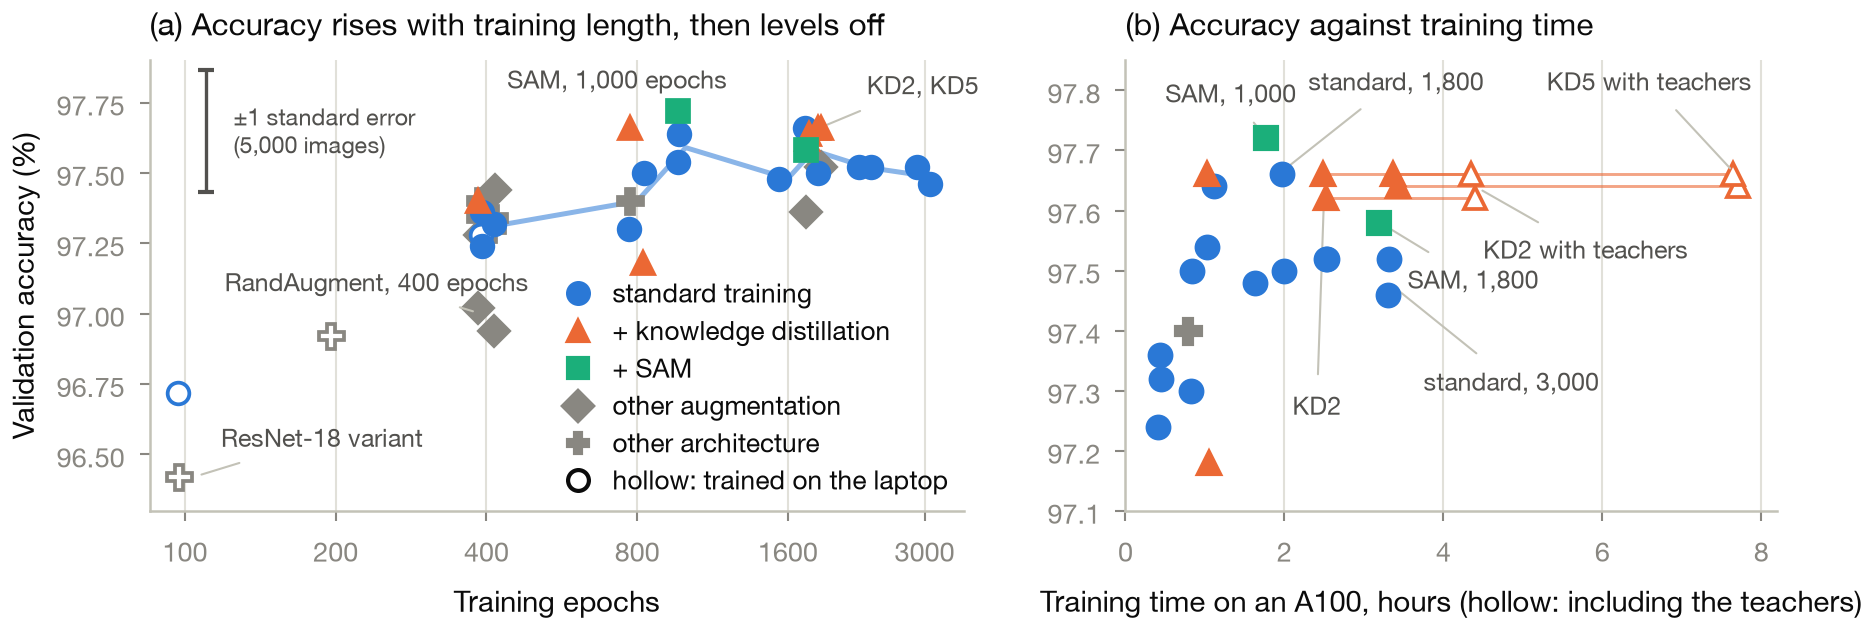

In [14]:
import importlib  # noqa: E402

sys.path.insert(0, str(FIGURES))
figures = importlib.import_module("make_results_figures")
figures.HERE = Path(tempfile.mkdtemp())  # where the figure functions write; their data folder stays report/figures/data
figures.schedule_figure()
show(figures.HERE / "schedule.png", 1000)

### Figure 3 and Section 3.4: training curves

The three 1,800-epoch runs with seed 2026 (standard training, KD2, SAM). (a) Validation accuracy of the EMA weights with
flip test-time augmentation, evaluated every ten epochs. (b) The last 800 epochs. (c) Accuracy on the augmented training
batches. The three curves follow each other closely for the first 1,500 epochs, and all still gain 0.2 to 0.4 points in
the last 300 as the learning rate decays to zero (the numbers are printed under the figure). Training accuracy ends at
93 to 94%, four points below validation accuracy, so strong augmentation remains the main source of regularization until
the end of training.

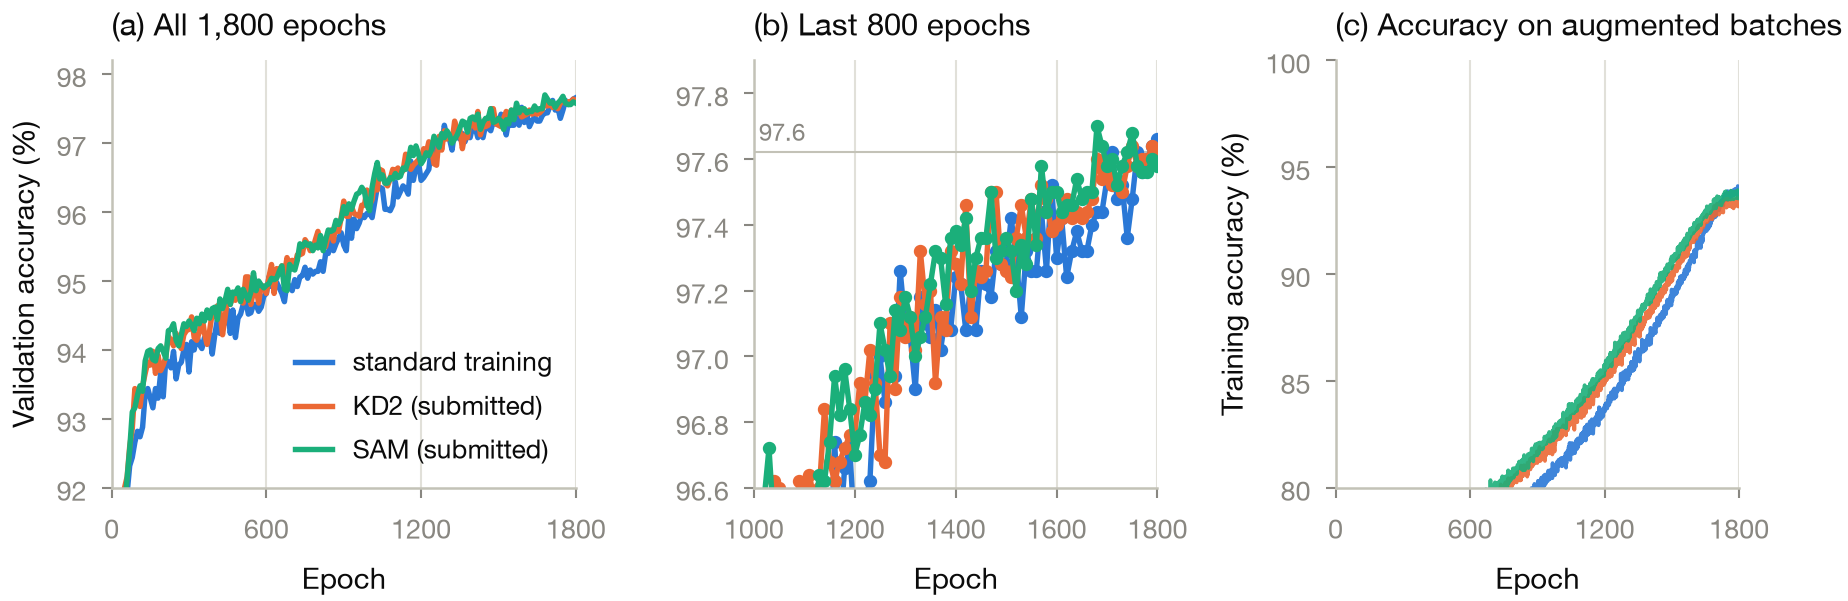

standard training  validation accuracy at epoch 1,500: 97.28%, at epoch 1,800: 97.66% (+0.38); training accuracy at the end: 93.8%
KD2                validation accuracy at epoch 1,500: 97.26%, at epoch 1,800: 97.62% (+0.36); training accuracy at the end: 93.4%
SAM                validation accuracy at epoch 1,500: 97.36%, at epoch 1,800: 97.58% (+0.22); training accuracy at the end: 93.7%


In [15]:
figures.curves_figure()
show(figures.HERE / "curves.png", 1000)
curves = json.loads((DATA / "curves_1800.json").read_text())
for run, name in (("r2-ta1800-s2026", "standard training"), ("r2-kd2-ta1800-s2026", "KD2"), ("sam-x4-1800-s2026", "SAM")):
    at = dict(zip(curves[run]["epoch"], curves[run]["tta_valid_accuracy"]))
    print(f"{name:18s} validation accuracy at epoch 1,500: {100 * at[1500]:.2f}%, at epoch 1,800: {100 * at[1800]:.2f}% "
          f"(+{100 * (at[1800] - at[1500]):.2f}); training accuracy at the end: {100 * curves[run]['train_accuracy'][-1]:.1f}%")

## Hidden test set (Section 3.5, Table 6)

One receipt was recorded for each of the 21 uploads (`artifacts/kaggle_submissions.jsonl`): the hash of the CSV, the
checkpoint, and the public and private scores that Kaggle returned. `report/figures/data/submissions.csv` is the same
information as a table, with the validation accuracy of each model. Kaggle scores a team on at most two selected
submissions and by default selects the two with the highest public scores. The validation set does not single out two
models, so this default was kept: the KD2 and SAM models. The final ranking uses the better private score of the two.

The table lists all 21 submissions. "Drop" is the public score minus the private score, and "all 2,000" is the mean of
the two halves of the test set.

In [16]:
for row in submissions:  # the table and the receipts must give the same scores
    receipt = receipts[int(row["kaggle_ref"])]
    assert abs(float(row["public"]) - 100 * receipt["public_score"]) < 1e-6 and abs(float(row["private"]) - 100 * receipt["private_score"]) < 1e-6
selected = [row for row in submissions if row["note"] == "selected"]
assert {int(row["kaggle_ref"]) for row in selected} == {item["receipt"] for item in FINAL.values()} \
    == {ref for ref, r in receipts.items() if str(r["selected_for_final"]).startswith("yes")}


def describe(row):
    """A submission in the report's terms: architecture, training method, number of epochs."""
    return f"{REPORT_NAME[row['arch']]}, {method_of(row['label'])}, {int(row['epochs']):,} epochs" + (", repeat" if "control" in row["label"] else "")


print(f"{'Kaggle ref':>10s}  {'submission':47s} {'seed':>4s} {'images':>7s} {'validation':>10s} {'public':>7s} {'private':>8s} {'drop':>5s} {'all 2,000':>9s}")
for row in submissions:
    public, private = float(row["public"]), float(row["private"])
    print(f"{row['kaggle_ref']:>10s}  {describe(row):47s} {row['seed']:>4s} {int(row['train_images']):>7,} {row['heldout'] or '-':>10s} "
          f"{public:>7.1f} {private:>8.1f} {public - private:>5.1f} {(public + private) / 2:>9.2f}{'   <- selected' if row in selected else ''}")

Kaggle ref  submission                                      seed  images validation  public  private  drop all 2,000
  57784806  r18-64-352, standard training, 100 epochs       2026  45,000      96.42    86.3     84.7   1.6     85.50
  57795098  r18-64-352, standard training, 200 epochs       2026  50,000          -    87.8     85.1   2.7     86.45
  57795621  r18-w32, baseline training, 100 epochs          2026  45,000      94.84    83.8     80.6   3.2     82.20
  57799551  r18-w32, standard training, 100 epochs          2026  45,000      94.72    85.0     82.8   2.2     83.90
  57799552  r20-x4, standard training, 100 epochs           2026  45,000      96.72    86.6     84.9   1.7     85.75
  57799554  r18-64-352, standard training, 200 epochs       2026  45,000      96.92    88.2     85.5   2.7     86.85
  57858707  r20-x4, KD, 800 epochs                          2026  45,000      97.66    88.7     86.6   2.1     87.65
  57858708  r20-x4, standard training, 1,000 epochs         2026

Every number of Section 3.5, recomputed from the table above. The statistics of the leaderboard as a whole (number of
teams, rank, median, the mean loss of all teams) cannot be computed from our own submissions; they were read from Kaggle
after the competition closed and are stored in `artifacts/kaggle_leaderboard.json`.

In [17]:
start = len(CHECKS)
public = np.array([float(row["public"]) for row in submissions])
private = np.array([float(row["private"]) for row in submissions])
board = json.loads((ROOT / "artifacts/kaggle_leaderboard.json").read_text())
finals = {key: by_ref[item["receipt"]] for key, item in FINAL.items()}
final_score = max(float(row["private"]) for row in selected)
assert board["private"]["team_score"] == final_score and board["public"]["team_score"] == public.max()

print("The selection and the final result")
check("submissions uploaded", len(submissions), 21, 0)
check("KD2, public accuracy (%)", float(finals["KD2"]["public"]), 90.1, 1)
check("SAM, public accuracy (%)", float(finals["SAM"]["public"]), 90.0, 1)
check("final test accuracy: the better private score of the two selected submissions (%)", final_score, 87.4, 1)
check("KD2, private accuracy (%)", float(finals["KD2"]["private"]), 87.1, 1)
check("SAM, all 2,000 test images (%)", (float(finals["SAM"]["public"]) + float(finals["SAM"]["private"])) / 2, 88.7, 1)
check("KD2, all 2,000 test images (%)", (float(finals["KD2"]["public"]) + float(finals["KD2"]["private"])) / 2, 88.6, 1)
print(f"    leaderboard, read from Kaggle on {board['retrieved']}: private rank {board['private']['rank']} of {board['teams']} teams, "
      f"median {board['private']['median_score']}%, 16th place (the top 20%) {board['private']['rank_16_score']}%; "
      f"final public rank {board['public']['rank']} of {board['teams']}")

print("\nConclusion 1: the private half of the test set is harder than the public half")
drop = public - private
print(f"    submissions that score lower on the private half: {int((drop > 0).sum())} of {len(drop)}; mean drop {drop.mean():.2f} points")
check("smallest drop from public to private (points)", drop.min(), 1.2, 1)
check("largest drop from public to private (points)", drop.max(), 3.3, 1)
print(f"    mean drop of all {board['teams']} teams, read from the leaderboard: {board['mean_public_minus_private_over_teams']} points")

print("\nConclusion 2: progress on the validation set carried over to the test set")
scored = [row for row in submissions if row["heldout"]]
validation = np.array([float(row["heldout"]) for row in scored])
check("submissions with a validation score", len(scored), 18, 0)
check("correlation of validation and private accuracy over them", np.corrcoef(validation, [float(row["private"]) for row in scored])[0, 1], 0.95)

print("\nConclusion 3: the ten models with the highest validation accuracy cannot be separated")
top = sorted(scored, key=lambda row: -float(row["heldout"]))[:10]
top_validation, top_public, top_private = (np.array([float(row[column]) for row in top]) for column in ("heldout", "public", "private"))
check("lowest validation accuracy of the ten (%)", top_validation.min(), 97.54)
check("highest validation accuracy of the ten (%)", top_validation.max(), 97.72)
print(f"    their validation accuracies span {top_validation.max() - top_validation.min():.2f} points; one standard error on 5,000 images is "
      f"{100 * math.sqrt(0.976 * 0.024 / 5000):.2f}")
check("lowest private accuracy of the ten (%)", top_private.min(), 86.2, 1)
check("highest private accuracy of the ten (%)", top_private.max(), 87.4, 1)
print(f"    their private accuracies span {top_private.max() - top_private.min():.1f} points; one standard error of 87% on 1,000 images is "
      f"{100 * math.sqrt(0.87 * 0.13 / 1000):.2f}")
check("correlation of validation and private accuracy among the ten", np.corrcoef(top_validation, top_private)[0, 1], 0.02)
check("correlation of public and private accuracy among the ten", np.corrcoef(top_public, top_private)[0, 1], -0.01)
best = max(submissions, key=lambda row: float(row["private"]))
print(f"    highest private score of all 21 submissions: {describe(best)}, seed {best['seed']}, trained on {int(best['train_images']):,} images")
check("highest private score among all our submissions (%)", float(best["private"]), 87.6, 1)
check("its margin over our final score (points)", float(best["private"]) - final_score, 0.2, 1)

print("\nTable 6: the two final submissions, the next four public scores and the highest private score")
TABLE6 = [(57959285, 97.62, 90.1, 87.1), (58002253, 97.58, 90.0, 87.4), (57959296, 97.64, 89.7, 86.5), (57963791, 97.66, 89.7, 86.4),
          (58050592, None, 89.7, 87.0), (57858708, 97.54, 89.5, 86.2), (58028537, None, 88.8, 87.6)]  # Kaggle reference, validation, public, private
table6 = sorted(submissions, key=lambda row: -float(row["public"]))[:6] + [best]
assert [int(row["kaggle_ref"]) for row in table6] == [ref for ref, *_ in TABLE6]
for row, (ref, reported_validation, reported_public, reported_private) in zip(table6, TABLE6):
    print(f"    {describe(row):41s} seed {row['seed']}  {int(row['train_images']):>6,} images  validation {row['heldout'] or '-':>5s}  public {row['public']}  private {row['private']}")
    if reported_validation is not None:
        check(f"Table 6, {ref}: validation", float(row["heldout"]), reported_validation, quiet=True)
    check(f"Table 6, {ref}: public", float(row["public"]), reported_public, 1, quiet=True)
    check(f"Table 6, {ref}: private", float(row["private"]), reported_private, 1, quiet=True)
summarize(start)

The selection and the final result
    submissions uploaded: 21   (report: 21)
    KD2, public accuracy (%): 90.1   (report: 90.1)
    SAM, public accuracy (%): 90.0   (report: 90.0)
    final test accuracy: the better private score of the two selected submissions (%): 87.4   (report: 87.4)
    KD2, private accuracy (%): 87.1   (report: 87.1)
    SAM, all 2,000 test images (%): 88.7   (report: 88.7)
    KD2, all 2,000 test images (%): 88.6   (report: 88.6)
    leaderboard, read from Kaggle on 2026-11-09: private rank 27 of 81 teams, median 86.9%, 16th place (the top 20%) 87.9%; final public rank 30 of 81

Conclusion 1: the private half of the test set is harder than the public half
    submissions that score lower on the private half: 21 of 21; mean drop 2.31 points
    smallest drop from public to private (points): 1.2   (report: 1.2)
    largest drop from public to private (points): 3.3   (report: 3.3)
    mean drop of all 81 teams, read from the leaderboard: 2.83 points

Conclusion 

The same three conclusions as a picture (this chart is not in the report). (a) Across all 18 submissions with a
validation score, a higher validation accuracy comes with a higher private accuracy. (b) Among the ten with the highest
validation accuracy, whose range is shaded in (a), validation accuracy says nothing about the private score, and the
three training methods are mixed. (c) Neither does the public score, which is what selected the two final submissions.
The bar in (b) and (c) is one standard error of an accuracy measured on the 1,000 private images.

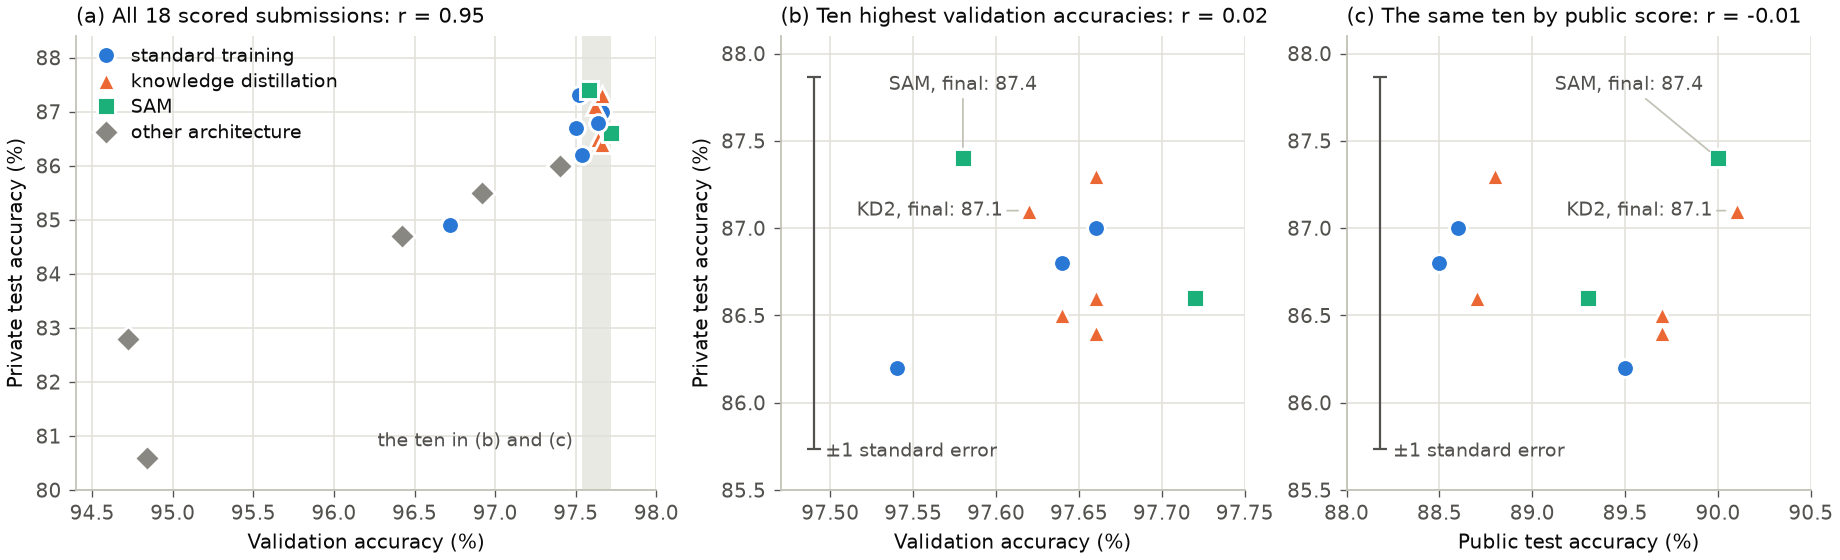

In [18]:
INK, SECONDARY, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
METHODS = {"standard training": ("#2a78d6", "o"), "knowledge distillation": ("#eb6834", "^"), "SAM": ("#1baf7a", "s")}


def series_of(row):
    """Marker of a submission: its training method for r20-x4, the neutral gray for the other architectures."""
    if row["arch"] != "resnet20-x4":
        return "other architecture", MUTED, "D"
    name = {"KD": "knowledge distillation", "SAM": "SAM"}.get(row["label"].split()[0].rstrip("25"), "standard training")
    return (name, *METHODS[name])


def scatter(ax, rows, column):
    for row in rows:
        _, color, marker = series_of(row)
        ax.plot(float(row[column]), float(row["private"]), marker=marker, ms=8, color=color, mec="white", mew=1.3, ls="none", zorder=3)


def label_finals(ax, column, offsets):
    for key, (dx, dy, align) in offsets.items():
        x, y = float(finals[key][column]), float(finals[key]["private"])
        ax.annotate(f"{key}, final: {y:.1f}", (x, y), xytext=(x + dx, y + dy), fontsize=8.5, color=SECONDARY, ha=align, va="center",
                    arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8, shrinkA=0, shrinkB=5))


with plt.style.context("default"):
    plt.rcParams.update({"font.size": 9, "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK, "text.color": INK,
                         "xtick.color": SECONDARY, "ytick.color": SECONDARY, "axes.titlesize": 9.5})
    fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(11.5, 3.5), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1, 1]})
    ax_a.axvspan(top_validation.min(), top_validation.max(), color=GRID, alpha=0.7, lw=0, zorder=1)
    ax_a.text(top_validation.min() - 0.06, 80.9, "the ten in (b) and (c)", fontsize=8.5, color=SECONDARY, ha="right", va="center")
    scatter(ax_a, scored, "heldout")
    scatter(ax_b, top, "heldout")
    scatter(ax_c, top, "public")
    r_all = np.corrcoef(validation, [float(row["private"]) for row in scored])[0, 1]
    ax_a.set_title(f"(a) All {len(scored)} scored submissions: r = {r_all:.2f}", loc="left")
    ax_b.set_title(f"(b) Ten highest validation accuracies: r = {np.corrcoef(top_validation, top_private)[0, 1]:.2f}", loc="left")
    ax_c.set_title(f"(c) The same ten by public score: r = {np.corrcoef(top_public, top_private)[0, 1]:.2f}", loc="left")
    ax_a.set(xlabel="Validation accuracy (%)", ylabel="Private test accuracy (%)", xlim=(94.4, 98.0), ylim=(80.0, 88.4))
    ax_b.set(xlabel="Validation accuracy (%)", ylabel="Private test accuracy (%)", xlim=(97.47, 97.75), ylim=(85.5, 88.1))
    ax_c.set(xlabel="Public test accuracy (%)", xlim=(88.0, 90.5), ylim=(85.5, 88.1))
    standard_error = 100 * math.sqrt(0.87 * 0.13 / 1000)
    for ax, x, text_x in ((ax_b, 97.49, 97.497), (ax_c, 88.18, 88.25)):
        ax.errorbar(x, 86.8, yerr=standard_error, color=SECONDARY, capsize=3, lw=1.0, zorder=2)
        ax.text(text_x, 85.72, "±1 standard error", fontsize=8.5, color=SECONDARY, ha="left", va="center")
    label_finals(ax_b, "heldout", {"SAM": (0.0, 0.42, "center"), "KD2": (-0.016, 0.0, "right")})
    label_finals(ax_c, "public", {"SAM": (-0.08, 0.42, "right"), "KD2": (-0.13, 0.0, "right")})
    for ax in (ax_a, ax_b, ax_c):
        ax.grid(color=GRID, lw=0.7)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(length=3, width=0.6)
    handles = [plt.Line2D([], [], marker=marker, color=color, mec="white", mew=1.3, ms=8, ls="none", label=name) for name, (color, marker) in METHODS.items()]
    handles.append(plt.Line2D([], [], marker="D", color=MUTED, mec="white", mew=1.3, ms=8, ls="none", label="other architecture"))
    ax_a.legend(handles=handles, loc="upper left", frameon=False, fontsize=8.5, handletextpad=0.3, labelspacing=0.35, borderaxespad=0.2)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=160, facecolor="white")
    plt.close(fig)
display(Image(data=buffer.getvalue(), width=1100))

## Error analysis (Section 3.6, Figures 4 to 6)

Section 3.6 analyses six models on the validation set, image by image: `r20-x4` and `r18-64-352` with standard training
for 100 epochs, and the four `r20-x4` models trained for 1,800 epochs (standard training, KD2 with two seeds, SAM). Every
number in it is stored in `report/figures/data/error_analysis.json`, which `report/figures/make_error_analysis.py` writes
from the checkpoints. The cell below repeats the computation for the checkpoints it finds and compares the result with
the file; only the two submitted models are released, so on another machine the cell checks those two and reads the rest
from the file. It uses the labeled validation images only.

In [19]:
ERROR_MODELS = {"r20-x4 standard 100": "improved100-resnet20-x4", "r18-64-352 standard 100": "improved100-resnet18-64-352",
                "r20-x4 standard 1800": "r2-ta1800-s2026", "r20-x4 KD2 1800 s2026": "r2-kd2-ta1800-s2026",
                "r20-x4 KD2 1800 s2027": "r2-kd2-ta1800-s2027", "r20-x4 SAM 1800": "sam-x4-1800-s2026"}
LONG = ["r20-x4 standard 1800", "r20-x4 KD2 1800 s2026", "r20-x4 KD2 1800 s2027", "r20-x4 SAM 1800"]
SHORT, SUBMITTED = "r20-x4 standard 100", "r20-x4 KD2 1800 s2026"
ANIMALS = {2, 3, 4, 5, 6, 7}
analysis_file = json.loads((DATA / "error_analysis.json").read_text())


def agree(a, b, tolerance=1e-4):
    """Equality of two nested results; floating-point values may differ by the tolerance."""
    if isinstance(a, dict):
        return a.keys() == b.keys() and all(agree(a[k], b[k], tolerance) for k in a)
    if isinstance(a, (list, tuple)):
        return len(a) == len(b) and all(agree(x, y, tolerance) for x, y in zip(a, b))
    return abs(a - b) <= tolerance if isinstance(a, float) or isinstance(b, float) else a == b


def model_statistics(probabilities, labels):
    predicted = probabilities.argmax(1)
    wrong = predicted != labels
    matrix = confusion(predicted, labels)
    confidence, second = probabilities.max(1), np.argsort(probabilities, 1)[:, -2]
    return {"accuracy": float((~wrong).mean()), "errors": int(wrong.sum()),
            "per_class": [float(matrix[i, i] / matrix[i].sum()) for i in range(10)],
            "errors_per_class": [int(matrix[i].sum() - matrix[i, i]) for i in range(10)],
            "confusion": matrix.tolist(), "cat_dog_confusions": int(matrix[3, 5] + matrix[5, 3]),
            "confidence_correct_mean": float(confidence[~wrong].mean()), "confidence_wrong_mean": float(confidence[wrong].mean()),
            "confidence_correct_median": float(np.median(confidence[~wrong])),
            "errors_above_correct_median": int((confidence[wrong] >= np.median(confidence[~wrong])).sum()),
            "errors_with_confidence_at_least_0.5": int((confidence[wrong] >= 0.5).sum()),
            "errors_where_true_class_is_second_choice": int((second[wrong] == labels[wrong]).sum())}


probabilities = {}
for name, run in ERROR_MODELS.items():
    if find_checkpoint(run) is not None:
        network, _ = load_checkpoint_model(str(find_checkpoint(run)), device)
        probabilities[name], labels = validation_probabilities(network, device)
predicted = {name: p.argmax(1) for name, p in probabilities.items()}
wrong = {name: predicted[name] != labels for name in probabilities}

print(f"{'model':26s} {'errors':>6s} {'cat-dog':>8s} {'true class is 2nd choice':>25s} {'confidence wrong / correct':>27s}   recomputed from its checkpoint")
for name in ERROR_MODELS:
    stored = analysis_file["models"][name]
    status = f"equal to the file: {agree(model_statistics(probabilities[name], labels), stored)}" if name in probabilities else "checkpoint not available"
    print(f"{name:26s} {stored['errors']:>6d} {stored['cat_dog_confusions']:>8d} {stored['errors_where_true_class_is_second_choice']:>25d} "
          f"{stored['confidence_wrong_mean']:>12.2f} / {stored['confidence_correct_mean']:.2f}          {status}")

if SUBMITTED in probabilities:
    matrix = confusion(predicted[SUBMITTED], labels)
    vehicles = set(range(10)) - ANIMALS
    pairs = sorted(((int(matrix[i, j] + matrix[j, i]), CLASSES[i], CLASSES[j]) for i, j in combinations(range(10), 2)), reverse=True)
    groups = {"within_animals": int(sum(matrix[i, j] for i in ANIMALS for j in ANIMALS if i != j)),
              "within_vehicles": int(sum(matrix[i, j] for i in vehicles for j in vehicles if i != j)),
              "across": int(sum(matrix[i, j] for i in range(10) for j in range(10) if i != j and ((i in ANIMALS) != (j in ANIMALS)))),
              "largest_unordered_pairs": [list(pair) for pair in pairs[:6]]}
    heldout_eval = json.loads((DATA / "heldout_eval.json").read_text())
    print(f"\nerrors of the KD2 model by group of classes, equal to the file: {agree(groups, analysis_file['final_model_groups'])}; "
          f"its confusion matrix equals the one Figure 4 is drawn from: {matrix.tolist() == heldout_eval['kd2-s2026']['confusion']}")
if all(name in probabilities for name in LONG + [SHORT]):
    all_four = np.logical_and.reduce([wrong[name] for name in LONG])
    how_many = np.sum([wrong[name] for name in LONG], axis=0)
    same_answer = all_four & np.all([predicted[name] == predicted[LONG[0]] for name in LONG], axis=0)
    shared = {"wrong_in_all_four": int(all_four.sum()), "wrong_in_at_least_one": int((how_many > 0).sum()),
              "wrong_in_exactly": {str(k): int((how_many == k).sum()) for k in range(1, 5)},
              "all_four_same_wrong_answer": int(same_answer.sum()),
              "wrong_in_all_four_per_class": {CLASSES[c]: int(n) for c, n in Counter(labels[all_four].tolist()).items()},
              "wrong_in_all_four_also_wrong_at_100_epochs": int((all_four & wrong[SHORT]).sum())}
    between = {f"{a} | {b}": {"errors_a": int(wrong[a].sum()), "errors_b": int(wrong[b].sum()), "both_wrong": int((wrong[a] & wrong[b]).sum())}
               for a, b in combinations(LONG, 2)}
    before, after = wrong[SHORT], wrong["r20-x4 standard 1800"]
    length = {"errors_100": int(before.sum()), "errors_1800": int(after.sum()), "still_wrong": int((before & after).sum()),
              "fixed": int((before & ~after).sum()), "new": int((~before & after).sum()),
              "errors_100_per_class": [int((before & (labels == c)).sum()) for c in range(10)],
              "errors_1800_per_class": [int((after & (labels == c)).sum()) for c in range(10)]}
    mean_probabilities = np.mean([probabilities[name] for name in LONG], axis=0)
    hardest = np.where(same_answer)[0]
    hardest = hardest[np.argsort(-mean_probabilities[hardest].max(1))][:12]
    positions = np.load(ROOT / "data/cache/split.npz")["valid"]
    hard = [{"validation_position": int(i), "train_index": int(positions[i]), "true": CLASSES[labels[i]],
             "predicted": CLASSES[predicted[LONG[0]][i]], "mean_confidence": float(mean_probabilities[i].max())} for i in hardest]
    print("recomputed from all six checkpoints and equal to the file: "
          f"errors shared by the four 1,800-epoch models {agree(shared, analysis_file['long_models'])}, "
          f"pairs of models {agree(between, analysis_file['pairs'])}, 100 against 1,800 epochs {agree(length, analysis_file['training_length'])}, "
          f"the twelve images of Figure 6 {agree(hard, analysis_file['hard_examples'])}")
else:
    print("the comparisons between models need all six checkpoints; they are read from the file")

model                      errors  cat-dog  true class is 2nd choice  confidence wrong / correct   recomputed from its checkpoint
r20-x4 standard 100           164       34                       114         0.60 / 0.89          equal to the file: True
r18-64-352 standard 100       179       41                       127         0.61 / 0.89          equal to the file: True
r20-x4 standard 1800          117       35                        89         0.65 / 0.90          equal to the file: True
r20-x4 KD2 1800 s2026         119       33                        97         0.69 / 0.90          equal to the file: True
r20-x4 KD2 1800 s2027         117       31                        86         0.66 / 0.90          equal to the file: True
r20-x4 SAM 1800               121       33                        97         0.60 / 0.89          equal to the file: True

errors of the KD2 model by group of classes, equal to the file: True; its confusion matrix equals the one Figure 4 is drawn from: True
re

**Figure 4: validation confusion matrix of the KD2 model.** Diagonal cells show the accuracy of each class in percent,
and off-diagonal cells show error counts out of 500 images per class. The numbers under the figure are those of the first
paragraph of Section 3.6: the errors fall mostly within the animal classes, and most of them are near misses.

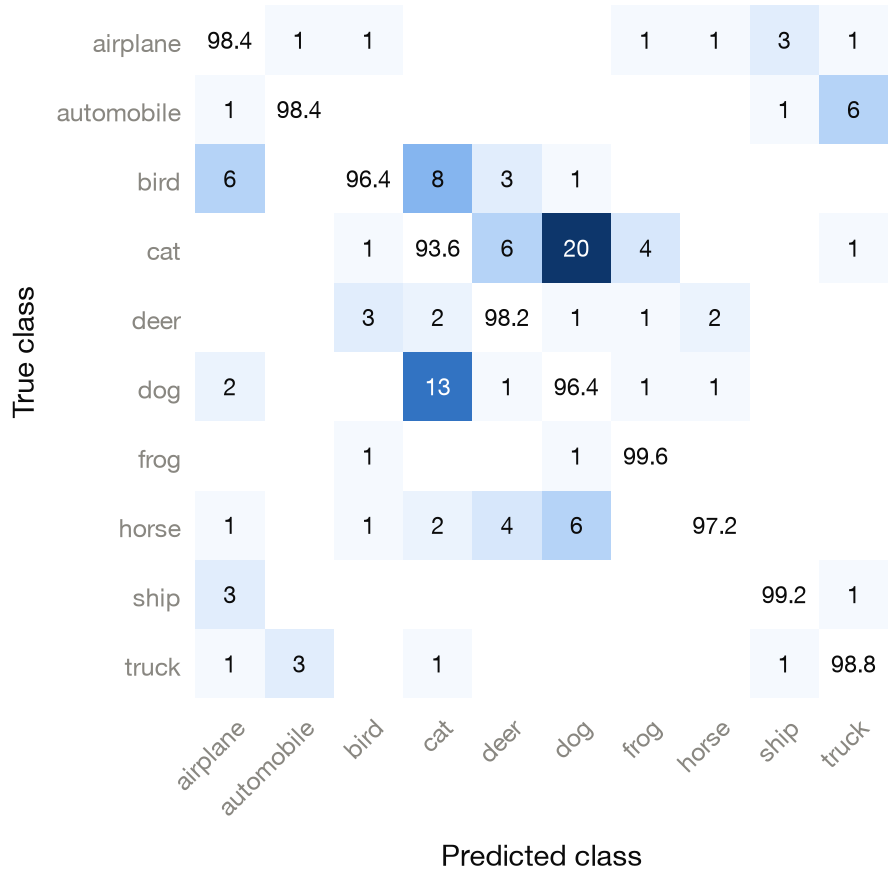

    errors of the KD2 model on the 5,000 validation images: 119   (report: 119)
    errors that confuse two animal classes: 83   (report: 83)
    errors that confuse two vehicle classes: 22   (report: 22)
    errors between an animal and a vehicle: 14   (report: 14)
    accuracy on cat, the hardest class (%): 93.6   (report: 93.6)
    confusions between cat and dog: 33   (report: 33)
    errors where the true class is the second choice: 97   (report: 97)
    mean confidence on wrong predictions: 0.69   (report: 0.69)
    mean confidence on correct predictions: 0.90   (report: 0.90)
--> 9 numbers compared with the report: all agree.


In [20]:
figures.confusion_figure()
show(figures.HERE / "confusion.png", 520)
start = len(CHECKS)
kd2, groups_file = analysis_file["models"][SUBMITTED], analysis_file["final_model_groups"]
check("errors of the KD2 model on the 5,000 validation images", kd2["errors"], 119, 0)
check("errors that confuse two animal classes", groups_file["within_animals"], 83, 0)
check("errors that confuse two vehicle classes", groups_file["within_vehicles"], 22, 0)
check("errors between an animal and a vehicle", groups_file["across"], 14, 0)
check("accuracy on cat, the hardest class (%)", 100 * kd2["per_class"][CLASSES.index("cat")], 93.6, 1)
check("confusions between cat and dog", kd2["cat_dog_confusions"], 33, 0)
check("errors where the true class is the second choice", kd2["errors_where_true_class_is_second_choice"], 97, 0)
check("mean confidence on wrong predictions", kd2["confidence_wrong_mean"], 0.69)
check("mean confidence on correct predictions", kd2["confidence_correct_mean"], 0.90)
summarize(start)

**Figure 5: validation errors.** (a) Errors per class of `r20-x4` with standard training after 100 and after 1,800
epochs: longer training removes errors in the eight classes other than cat and dog, and none in cat and dog together.
(b) The number of images that exactly one, two, three or all four of the 1,800-epoch models get wrong: the four models
share about half of their errors.

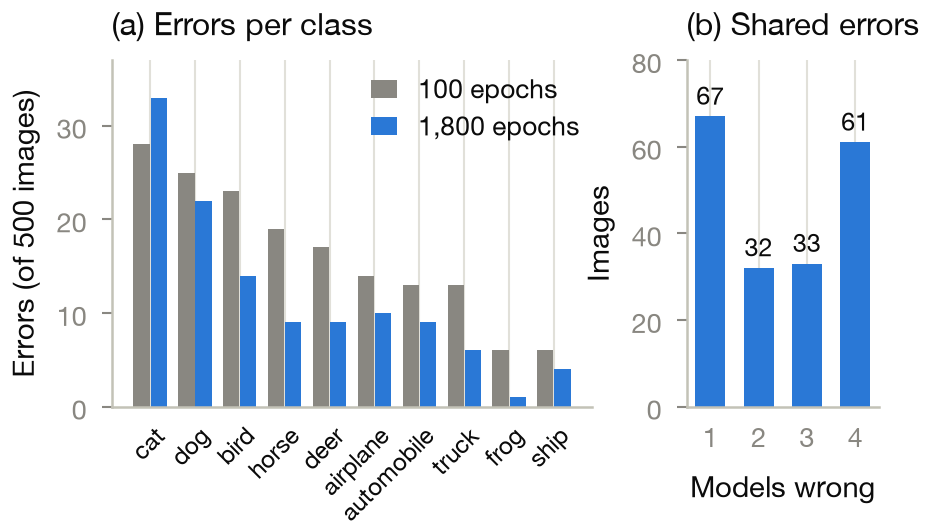

    errors after 100 epochs: 164   (report: 164)
    errors after 1,800 epochs: 117   (report: 117)
    errors in the eight other classes after 100 epochs: 111   (report: 111)
    errors in the eight other classes after 1,800 epochs: 62   (report: 62)
    errors in cat and dog after 100 epochs: 53   (report: 53)
    errors in cat and dog after 1,800 epochs: 55   (report: 55)
    fewest confusions between cat and dog among the four 1,800-epoch models: 31   (report: 31)
    most confusions between cat and dog among the four 1,800-epoch models: 35   (report: 35)
    images that all four 1,800-epoch models get wrong: 61   (report: 61)
    of these, images with the same wrong answer from all four: 55   (report: 55)
    of these, cats or dogs: 27   (report: 27)
    of these, images already wrong after 100 epochs: 52   (report: 52)
    share of each 1,800-epoch model's errors that all four models make: 0.52, 0.51, 0.52, 0.50
--> 12 numbers compared with the report: all agree.


In [21]:
figures.errors_figure()
show(figures.HERE / "errors.png", 620)
start = len(CHECKS)
length_file, shared_file = analysis_file["training_length"], analysis_file["long_models"]
cat_dog = [CLASSES.index("cat"), CLASSES.index("dog")]
others = [c for c in range(10) if c not in cat_dog]
errors_100, errors_1800 = np.array(length_file["errors_100_per_class"]), np.array(length_file["errors_1800_per_class"])
check("errors after 100 epochs", length_file["errors_100"], 164, 0)
check("errors after 1,800 epochs", length_file["errors_1800"], 117, 0)
check("errors in the eight other classes after 100 epochs", errors_100[others].sum(), 111, 0)
check("errors in the eight other classes after 1,800 epochs", errors_1800[others].sum(), 62, 0)
check("errors in cat and dog after 100 epochs", errors_100[cat_dog].sum(), 53, 0)
check("errors in cat and dog after 1,800 epochs", errors_1800[cat_dog].sum(), 55, 0)
cat_dog_long = [analysis_file["models"][name]["cat_dog_confusions"] for name in LONG]
check("fewest confusions between cat and dog among the four 1,800-epoch models", min(cat_dog_long), 31, 0)
check("most confusions between cat and dog among the four 1,800-epoch models", max(cat_dog_long), 35, 0)
check("images that all four 1,800-epoch models get wrong", shared_file["wrong_in_all_four"], 61, 0)
check("of these, images with the same wrong answer from all four", shared_file["all_four_same_wrong_answer"], 55, 0)
check("of these, cats or dogs", shared_file["wrong_in_all_four_per_class"]["cat"] + shared_file["wrong_in_all_four_per_class"]["dog"], 27, 0)
check("of these, images already wrong after 100 epochs", shared_file["wrong_in_all_four_also_wrong_at_100_epochs"], 52, 0)
print("    share of each 1,800-epoch model's errors that all four models make: "
      + ", ".join(f"{shared_file['wrong_in_all_four'] / analysis_file['models'][name]['errors']:.2f}" for name in LONG))
summarize(start)

**Figure 6: the twelve validation images that all four 1,800-epoch models get wrong with the same answer and the highest
mean confidence.** Above each image are its true class and the class it was predicted as: pets that look alike or are
curled up, and objects in unusual settings. Neither longer training nor a different training method fixes these images.
`make_error_analysis.py` draws the figure from the six checkpoints; the committed file is shown, and the list under it
is the one stored in `error_analysis.json` (verified above when the checkpoints are available).

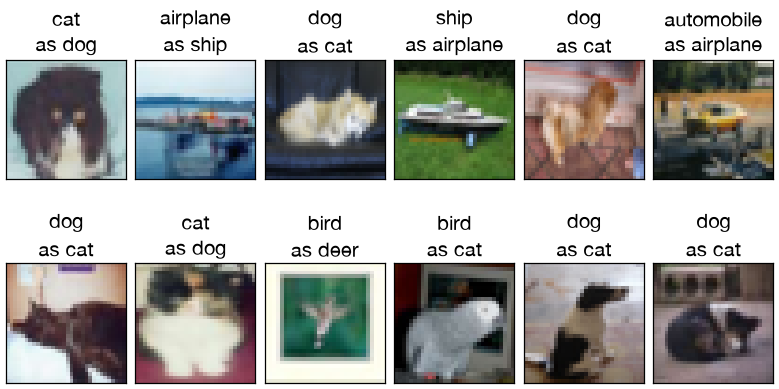

    training image 22239: cat        predicted as dog        mean confidence 0.91
    training image 45262: airplane   predicted as ship       mean confidence 0.91
    training image 19540: dog        predicted as cat        mean confidence 0.90
    training image 22616: ship       predicted as airplane   mean confidence 0.89
    training image 43404: dog        predicted as cat        mean confidence 0.89
    training image 13044: automobile predicted as airplane   mean confidence 0.88
    training image 10978: dog        predicted as cat        mean confidence 0.88
    training image 29084: cat        predicted as dog        mean confidence 0.87
    training image 31074: bird       predicted as deer       mean confidence 0.86
    training image 49419: bird       predicted as cat        mean confidence 0.86
    training image  4319: dog        predicted as cat        mean confidence 0.86
    training image 18151: dog        predicted as cat        mean confidence 0.85


In [22]:
show(FIGURES / "hard_examples.png", 620)
for example in analysis_file["hard_examples"]:
    print(f"    training image {example['train_index']:>5d}: {example['true']:10s} predicted as {example['predicted']:10s} mean confidence {example['mean_confidence']:.2f}")

## Final test accuracy and number of parameters

In [23]:
winner = max(FINAL, key=lambda key: float(finals[key]["private"]))
other = next(key for key in FINAL if key != winner)
for key in FINAL:
    receipt = receipts[FINAL[key]["receipt"]]
    assert receipt["parameter_count"] == final_parameters and receipt["arch"] == "resnet20-x4"
    assert abs(100 * receipt["private_score"] - float(finals[key]["private"])) < 1e-6
print("=" * 118)
print(f"FINAL TEST ACCURACY (Kaggle private leaderboard, 1,000 hidden test images): {float(finals[winner]['private']):.1f}%")
print(f"    {winner} model, run {FINAL[winner]['run']}, Kaggle submission {FINAL[winner]['receipt']}")
print(f"    public leaderboard (the other 1,000 test images): {float(finals[winner]['public']):.1f}%   all 2,000 test images: "
      f"{(float(finals[winner]['public']) + float(finals[winner]['private'])) / 2:.1f}%   validation (5,000 images): {float(finals[winner]['heldout']):.2f}%")
print(f"    second selected submission, {other} model ({FINAL[other]['receipt']}): private {float(finals[other]['private']):.1f}%, "
      f"public {float(finals[other]['public']):.1f}%, all 2,000 test images {(float(finals[other]['public']) + float(finals[other]['private'])) / 2:.1f}%, "
      f"validation {float(finals[other]['heldout']):.2f}%")
print(f"    rank {board['private']['rank']} of {board['teams']} teams on the private leaderboard (median {board['private']['median_score']}%)")
print(f"NUMBER OF TRAINABLE PARAMETERS: {final_parameters:,} (resnet20-x4, the network of both submissions; limit 5,000,000)")
print("=" * 118)
differ = [(what, computed, reported) for what, computed, reported, agrees in CHECKS if not agrees]
print(f"{len(CHECKS)} numbers quoted in the report were recomputed in this notebook: " + ("all agree with the report." if not differ else f"{len(differ)} differ: {differ}"))

FINAL TEST ACCURACY (Kaggle private leaderboard, 1,000 hidden test images): 87.4%
    SAM model, run sam-x4-1800-s2026, Kaggle submission 58002253
    public leaderboard (the other 1,000 test images): 90.0%   all 2,000 test images: 88.7%   validation (5,000 images): 97.58%
    second selected submission, KD2 model (57959285): private 87.1%, public 90.1%, all 2,000 test images 88.6%, validation 97.62%
    rank 27 of 81 teams on the private leaderboard (median 86.9%)
NUMBER OF TRAINABLE PARAMETERS: 4,327,754 (resnet20-x4, the network of both submissions; limit 5,000,000)
203 numbers quoted in the report were recomputed in this notebook: all agree with the report.
